# Exploratory Data Analysis (EDA)

Here we will connect to the database and process the raw files to build the dataset before creating our model. To do that, we will: 

- Perform analysis of categorical variables and codification
- Perform analysis of the numerical variables

******

## 0. Load the processed dataset

In [71]:
import pandas as pd

file_path = "/workspaces/Datathon_CodeSpace/Data/Datathon_processed_data_20261020.csv"

df = pd.read_csv(file_path)

# Display the first 5 rows
display(df.head())

# Check dimensions and column names
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia,temp_w,tmin_w,tmax_w,prcp_w,wspd_w,pres_w
0,PANADERIA,417,2021-05-01,NaN,4.038,72.0,290.736004,5,17.2,11.9,22.8,0.0,14.2,1014.0
1,PANADERIA,900,2021-05-01,NaN,0.865,651.0,563.114998,3,17.2,11.9,22.8,0.0,14.2,1014.0
2,PANADERIA,968,2021-05-01,NaN,2.163,450.0,973.350002,1,17.2,11.9,22.8,0.0,14.2,1014.0
3,PANADERIA,1043,2021-05-01,NaN,2.596,327.0,848.892002,2,17.2,11.9,22.8,0.0,14.2,1014.0
4,PANADERIA,1084,2021-05-01,NaN,0.865,423.0,365.895005,4,17.2,11.9,22.8,0.0,14.2,1014.0


Dataset shape: (10322, 14)
Columns: ['familia', 'articulo', 'fecha_venta', 'festivo', 'precio', 'cantidad', 'importe', 'orden_articulo_familia', 'temp_w', 'tmin_w', 'tmax_w', 'prcp_w', 'wspd_w', 'pres_w']


******

## 1. Initial inspection of the data

1. What means each variable?

In [72]:
df.sample(5)

,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia,temp_w,tmin_w,tmax_w,prcp_w,wspd_w,pres_w
4993,PASTELERIA,5403,2022-04-17,Domingo de Resurrección,39.544998,16.2,640.629013,2,20.9,14.2,33.1,0.0,14.9,1016.0
8926,PANADERIA,900,2023-01-23,NaN,1.050000,423.0,444.150005,3,10.3,7.4,15.4,0.0,20.1,1021.2
10237,PANADERIA,900,2023-04-25,NaN,1.050000,258.0,270.900004,3,19.4,14.0,28.3,0.0,11.8,1015.5
2353,BOLLERIA,3880,2021-10-12,Día de la Hispanidad (Fiesta Nacional de España),3.000000,300.0,900.000000,3,21.0,17.9,25.2,0.0,7.8,1018.1
2277,PANADERIA,1043,2021-10-07,NaN,2.740000,195.0,534.299998,2,21.0,17.6,26.0,0.0,11.2,1020.1


In [73]:
df.columns

Index(['familia', 'articulo', 'fecha_venta', 'festivo', 'precio', 'cantidad',
       'importe', 'orden_articulo_familia', 'temp_w', 'tmin_w', 'tmax_w',
       'prcp_w', 'wspd_w', 'pres_w'],
      dtype='str')

Variables meaning:
- familia: product family type
- tipo: type of transaction
- fechaventa: date (without hour)
- festivo: type of festivity (or non festivity "NaN)
- articulo: product id
- precio: product price
- orden_articulo_familia: within each product family, the product order based on its selling performance
- in_fecha_estudio: S means that transaction is included from the date range
- cantidad: amount of products 
- importe: amount x price = total amount
- tmin_w: minimum temperature that day
- tmax_w: maximum temperature that day
- prcp_w: rainning rate
- wspd_w: wind speed
= pres_w: air pressure

2. How many unique values are in each variable? What insights you may observe comparing unique values of price and article variables?

In [74]:
# 1. Numerical features
df.describe()

,articulo,precio,cantidad,importe,orden_articulo_familia,temp_w,tmin_w,tmax_w,prcp_w,wspd_w,pres_w
count,10322.000000,10322.000000,10322.000000,10322.000000,10322.000000,10322.000000,10322.000000,10322.000000,10225.000000,10322.000000,10322.000000
mean,3945.385197,15.398333,138.310118,462.617803,2.961538,19.373164,15.195786,24.894371,0.794455,14.354524,1018.058555
std,2404.409766,16.987621,148.941152,273.939861,1.395584,5.406506,5.565703,5.991496,4.305785,5.353082,5.158186
min,417.000000,0.865000,1.200000,9.000000,1.000000,7.300000,1.100000,13.300000,0.000000,6.100000,1004.400000
25%,1043.000000,2.591000,15.000000,288.000000,2.000000,14.500000,10.800000,19.600000,0.000000,10.900000,1014.500000
50%,5403.000000,3.545000,84.000000,405.059754,3.000000,19.300000,14.600000,24.700000,0.000000,12.500000,1017.300000
75%,6286.000000,34.091000,219.000000,569.453926,4.000000,23.900000,20.100000,29.600000,0.000000,16.900000,1021.000000
max,6549.000000,43.500000,1110.000000,3271.929962,5.000000,33.500000,27.500000,42.600000,46.800000,46.500000,1032.800000


In [75]:
# 2. Categorical features
df.describe(include='object')

/tmp/ipykernel_2843/3226657610.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,familia,fecha_venta,festivo
count,10322,10322,809
unique,3,730,26
top,PANADERIA,2021-05-01,Feria de Málaga
freq,3650,15,99


In [78]:
# 2. Convert fechaventa into date time format
df['fecha_venta'] = pd.to_datetime(df['fecha_venta'], errors='coerce')

In [79]:
# 2. Insights comparing unique values

# Granularity: variety of data in relation to the total number of records. Percentage of unique values.
# Cardinality: number of different values

df_insights = (
df.dtypes.to_frame("Tipo")
    .assign(Cardinalidad = df.nunique())
    .assign(Granularidad = df.nunique() / len(df) * 100)
    .assign(Nulos_Pct = df.isnull().sum() / len(df) * 100)
    .assign(Max = df.dropna().apply(max))
    .assign(Min = df.dropna().apply(min))
    .sort_values(
    by="Tipo",
    key=lambda col: col.astype(str)
))

print(df_insights)

                                  Tipo  Cardinalidad  Granularidad  Nulos_Pct  \
fecha_venta             datetime64[us]           730      7.072273   0.000000   
precio                         float64            44      0.426274   0.000000   
cantidad                       float64          1388     13.447006   0.000000   
importe                        float64          6171     59.784925   0.000000   
temp_w                         float64           200      1.937609   0.000000   
tmin_w                         float64           212      2.053866   0.000000   
tmax_w                         float64           220      2.131370   0.000000   
prcp_w                         float64            58      0.561907   0.939740   
wspd_w                         float64           196      1.898857   0.000000   
pres_w                         float64           217      2.102306   0.000000   
articulo                         int64            15      0.145321   0.000000   
orden_articulo_familia      

- "importe" and "cantidad" are the variables with more unique values, as they are related the total price of each transaction
-  The difference between the unique number of items or "articles" (15 unique values) and prices or "precio" (97 unique values) shows that prices of each article have changed


3. How many null values are in each variable?

In [80]:
# 3. Number of nulls

df_nulls_summary = (
df.dtypes.to_frame("Tipo")
    .assign(Nulos_amount = df.isnull().sum())
    .assign(Nulos_Pct = df.isnull().sum() / len(df) * 100)
    .sort_values(
    by="Tipo",
    key=lambda col: col.astype(str)
))

print(df_nulls_summary)

                                  Tipo  Nulos_amount  Nulos_Pct
fecha_venta             datetime64[us]             0   0.000000
precio                         float64             0   0.000000
cantidad                       float64             0   0.000000
importe                        float64             0   0.000000
temp_w                         float64             0   0.000000
tmin_w                         float64             0   0.000000
tmax_w                         float64             0   0.000000
prcp_w                         float64            97   0.939740
wspd_w                         float64             0   0.000000
pres_w                         float64             0   0.000000
articulo                         int64             0   0.000000
orden_articulo_familia           int64             0   0.000000
familia                            str             0   0.000000
festivo                            str          9513  92.162372


<Axes: >

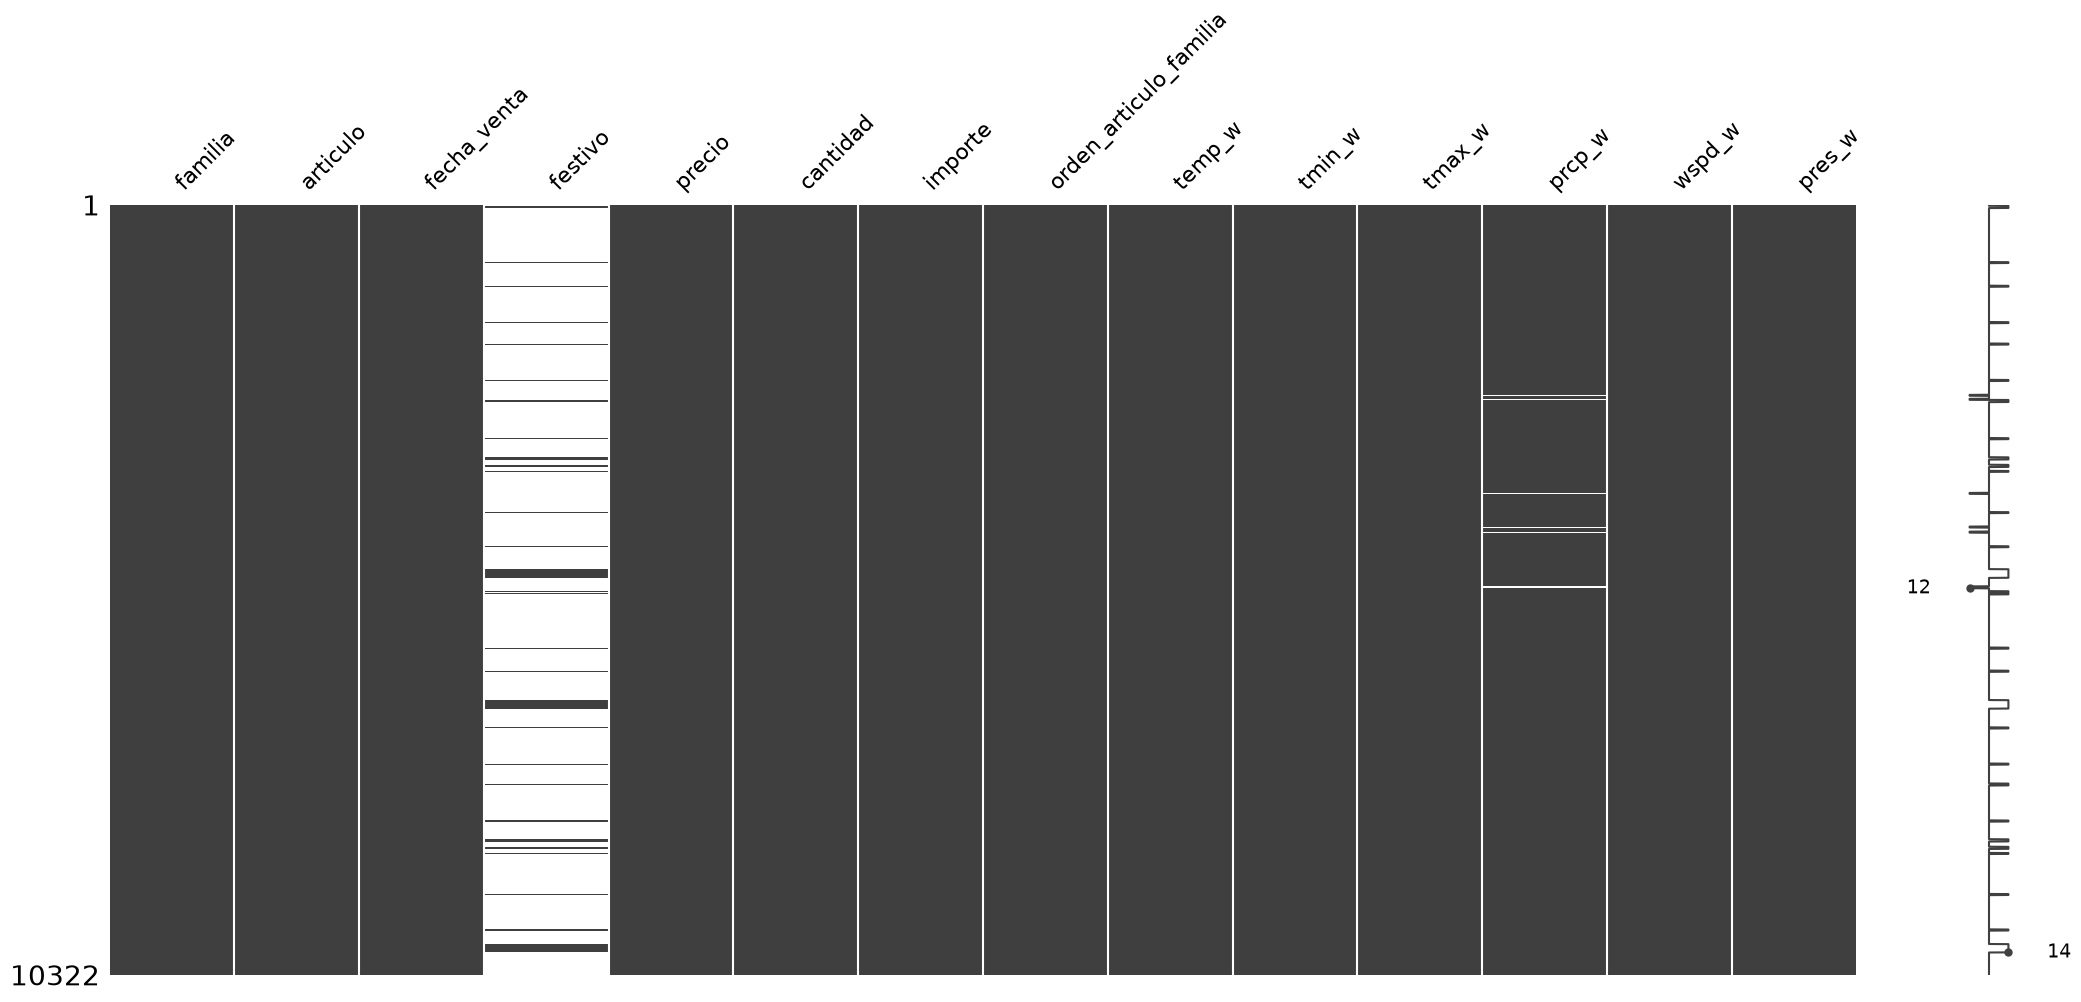

In [81]:
# 3. Null values
import missingno as msno

msno.matrix(df)

- "festivo" is the variable with more amount of "NaN" entries (9737, 92.084358% entries), and also "prcp_w" contains (97, 0.917344% entries) null entries


4. Are there duplicated values?

In [82]:
# 4. Duplicated values

nb_duplicated = df[df.duplicated(['fecha_venta', 'articulo'], keep=False)].shape[0]
#df.drop_duplicates(['fecha_venta', 'articulo'])
print(f"Number of duplicated rows based on 'fecha_venta' and 'articulo': {nb_duplicated}")

Number of duplicated rows based on 'fecha_venta' and 'articulo': 0


5. What's the date range in our dataset? If we divide by product, are there missing dates? Create a graph of the temporal evolution for the variable "amount" showing the "6549" article

In [83]:
print(df['fecha_venta'].dtype)
print(df['fecha_venta'].head())

datetime64[us]
0   2021-05-01
1   2021-05-01
2   2021-05-01
3   2021-05-01
4   2021-05-01
Name: fecha_venta, dtype: datetime64[us]


In [84]:
# 5. Range of dates in the dataset

min_date = df['fecha_venta'].min()
max_date = df['fecha_venta'].max()

print(f"Dataset contains values from {min_date} to {max_date}. ",
      f"Which represents a range of {max_date - min_date}")

Dataset contains values from 2021-05-01 00:00:00 to 2023-04-30 00:00:00.  Which represents a range of 729 days 00:00:00


- Dataset contains values from 2021-05-01 00:00:00 to 2023-05-18 00:00:00.  Which represents a range of 747 days 00:00:00

In [85]:
# 5. Check missing dates

# Get the unique ids of the articles
unique_articles = df.sort_values("familia")["articulo"].unique().tolist()

# Generate a variable with the date range
complete_range = pd.date_range(start=min_date, end=max_date, freq='D')

for article in unique_articles:

    #Filter the df for the article
    #subset = df.query("articulo == @article")
    subset = df[df['articulo'] == article]
    family = subset["familia"].unique().tolist()[0]

    # Let's see if there any date that is out of range
    missing_dates = complete_range.difference(subset['fecha_venta'])

    print(family, "-> Articulo", article, "-> Fechas faltantes", len(missing_dates))

BOLLERIA -> Articulo 6286 -> Fechas faltantes 2
BOLLERIA -> Articulo 5803 -> Fechas faltantes 3
BOLLERIA -> Articulo 6425 -> Fechas faltantes 1
BOLLERIA -> Articulo 3960 -> Fechas faltantes 0
BOLLERIA -> Articulo 3880 -> Fechas faltantes 0
PANADERIA -> Articulo 417 -> Fechas faltantes 0
PANADERIA -> Articulo 968 -> Fechas faltantes 0
PANADERIA -> Articulo 1043 -> Fechas faltantes 0
PANADERIA -> Articulo 1084 -> Fechas faltantes 0
PANADERIA -> Articulo 900 -> Fechas faltantes 0
PASTELERIA -> Articulo 6451 -> Fechas faltantes 73
PASTELERIA -> Articulo 5403 -> Fechas faltantes 103
PASTELERIA -> Articulo 6549 -> Fechas faltantes 304
PASTELERIA -> Articulo 5404 -> Fechas faltantes 94
PASTELERIA -> Articulo 6523 -> Fechas faltantes 48


- On one hand, there are articles that have been sold every recorded day such as article "3960", "3880", "968", "1084", "1043", "900" or "417"
- On the other hand, there are articles that are sold in very few days, such as article "6549" or "5303" with 312 and 107 missing recorded dates respectively


Text(0.5, 1.0, 'Evolución de ventas: (Artículo 6549)')

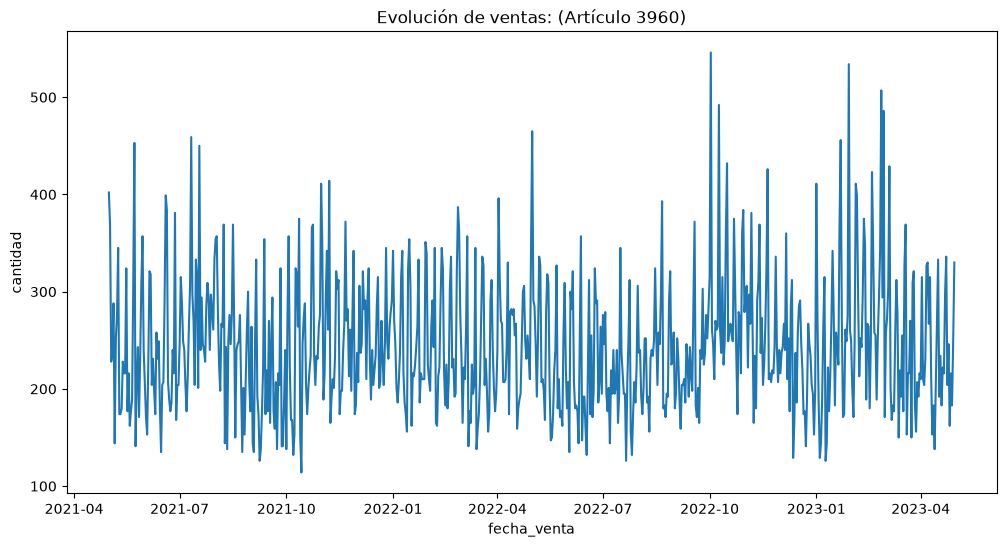

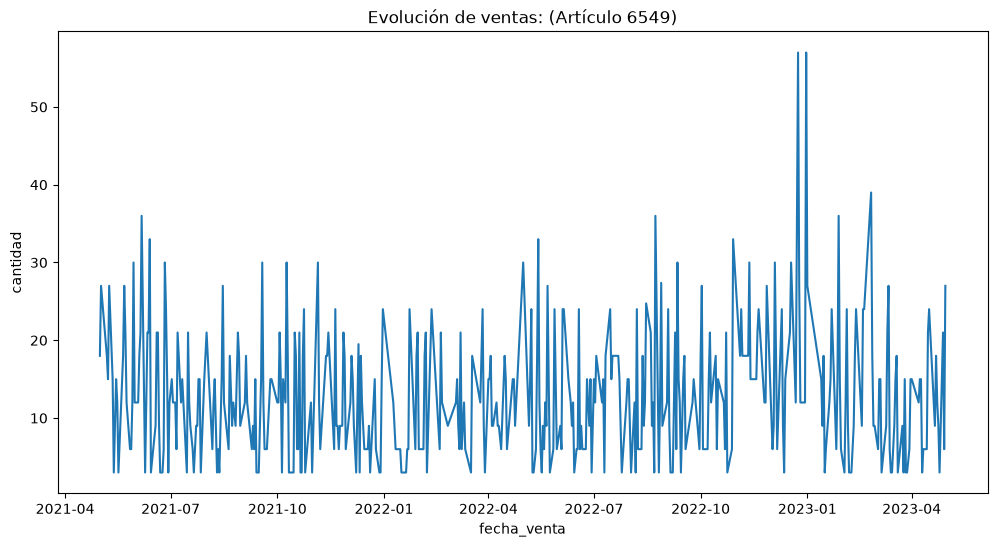

In [86]:
# 5. Plot the amount of the product "3960"
import matplotlib.pyplot as plt
import seaborn as sns

articulo = 3960
filtered_df = df[df['articulo'] == articulo]
plt.figure(figsize=(12, 6))
sns.lineplot(data=filtered_df, x='fecha_venta', y='cantidad')
plt.title(f'Evolución de ventas: (Artículo {articulo})')

articulo = 6549
filtered_df = df[df['articulo'] == articulo]
plt.figure(figsize=(12, 6))
sns.lineplot(data=filtered_df, x='fecha_venta', y='cantidad')
plt.title(f'Evolución de ventas: (Artículo {articulo})')


- Comparing these two articles, we can see that article "6549" is sold in lower amount and there are missing dates (connected by line gaps)

6. For each product, are there outliers of the variable "amount"?

In [87]:
# 6. Outliers in quantity by product

unique_articles = df.sort_values("familia")["articulo"].unique().tolist()

for article in unique_articles:

    subset = df[df['articulo'] == article]

    if subset.empty:
        continue

    family = subset['familia'].iloc[0]

    Q1 = subset['cantidad'].quantile(0.25)
    Q3 = subset['cantidad'].quantile(0.75)
    IQR = Q3 - Q1

    outliers = subset[
        (subset['cantidad'] < Q1 - 1.5 * IQR) |
        (subset['cantidad'] > Q3 + 1.5 * IQR)
    ]

    print(family, "-> Articulo", article, "-> Outliers", len(outliers))

BOLLERIA -> Articulo 6286 -> Outliers 57
BOLLERIA -> Articulo 5803 -> Outliers 52
BOLLERIA -> Articulo 6425 -> Outliers 25
BOLLERIA -> Articulo 3960 -> Outliers 15
BOLLERIA -> Articulo 3880 -> Outliers 36
PANADERIA -> Articulo 417 -> Outliers 19
PANADERIA -> Articulo 968 -> Outliers 27
PANADERIA -> Articulo 1043 -> Outliers 38
PANADERIA -> Articulo 1084 -> Outliers 6
PANADERIA -> Articulo 900 -> Outliers 31
PASTELERIA -> Articulo 6451 -> Outliers 22
PASTELERIA -> Articulo 5403 -> Outliers 38
PASTELERIA -> Articulo 6549 -> Outliers 3
PASTELERIA -> Articulo 5404 -> Outliers 25
PASTELERIA -> Articulo 6523 -> Outliers 35


<Axes: xlabel='cantidad'>

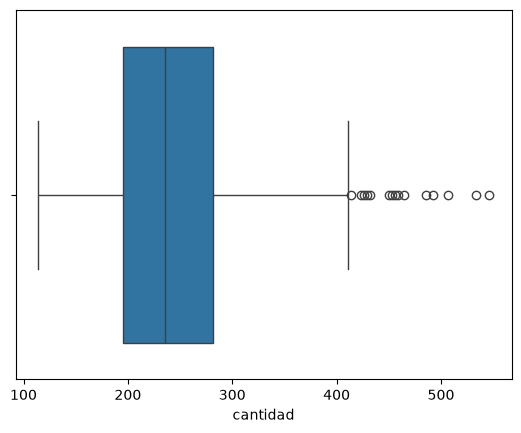

In [88]:
articulo_3960 = df[df['articulo'] == 3960]
sns.boxplot(data=articulo_3960, x='cantidad')

- Indeed we see a great number of mathematical outliers, however they may have sense if for instance, on festivity days a special type of product was specially sold. So, it may have sense

*****

#### 4.2. Analysis of the variable to predict

We aim to predict the amount of selling units ("amount" / "cantidad") variable of the product "3960". However, we will analyze the overal "amount" variable changes by product to see product trends

7. Create a graph of the general temporal evolution of the variable "cantidad"

<Axes: xlabel='fecha_venta', ylabel='cantidad'>

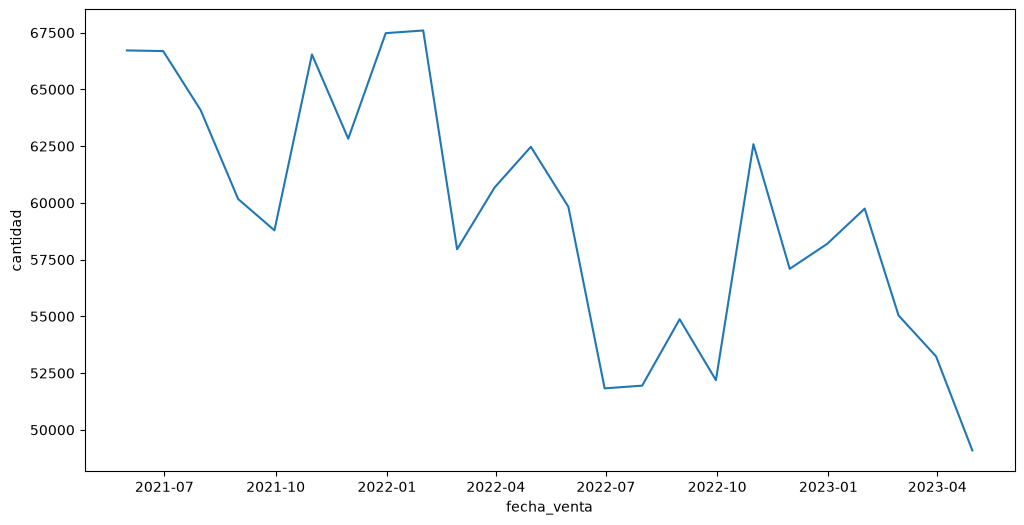

In [89]:
# 7. Temporal change of the variable "cantidad" where frequency can be days, months, years...

# group = df.groupby(pd.Grouper(key="fecha_venta", freq="D"))["cantidad"].sum().reset_index()
group = df.groupby(pd.Grouper(key="fecha_venta", freq="ME"))["cantidad"].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=group, x='fecha_venta', y='cantidad')

- We can see that there is a trend of lower amount of selling units along months

8. Create a graph of the temporal evolution of the variable "cantidad" grouping by family

<Figure size 1200x600 with 0 Axes>

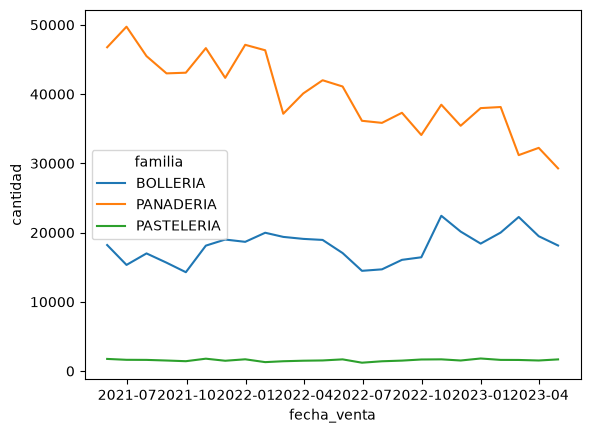

<Figure size 1200x600 with 0 Axes>

In [90]:
# 8. Temporal evolution of the variable "cantidad" by family

group = df.groupby(["familia", pd.Grouper(key="fecha_venta", freq="ME")])["cantidad"].sum().reset_index()
sns.lineplot(data=group, x='fecha_venta', y='cantidad', hue='familia')
plt.figure(figsize=(12, 6))

- We can see that less units from pasteleria and bolleria are sold, but these families remain stable whereas "panaderia" articles are the ones driving the loss of selling units over months

<Axes: xlabel='fecha_venta', ylabel='cantidad'>

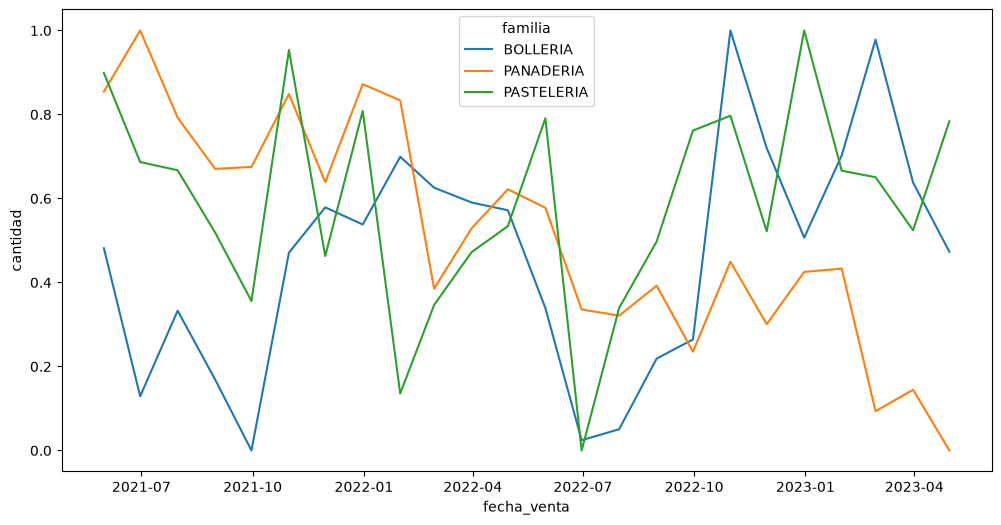

In [91]:
# 8. Evolution of the variable "cantidad" by family, normalized for comparison
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

def normalize(column):
    return scaler.fit_transform(column.values.reshape(-1, 1)).flatten()

group = df.groupby(["familia", pd.Grouper(key="fecha_venta", freq="ME")])["cantidad"].sum().reset_index()
group['cantidad'] = group.groupby('familia')['cantidad'].transform(normalize)
plt.figure(figsize=(12, 6))
sns.lineplot(data=group, x='fecha_venta', y='cantidad', hue='familia')

- Even if we normalize with a MinMaxScaler(), we can still see the trend that panaderia is progresivelly lossing selling units

9. Create a graph of the temporal evolution of the variable "cantidad" grouping by article

<Axes: xlabel='fecha_venta', ylabel='cantidad'>

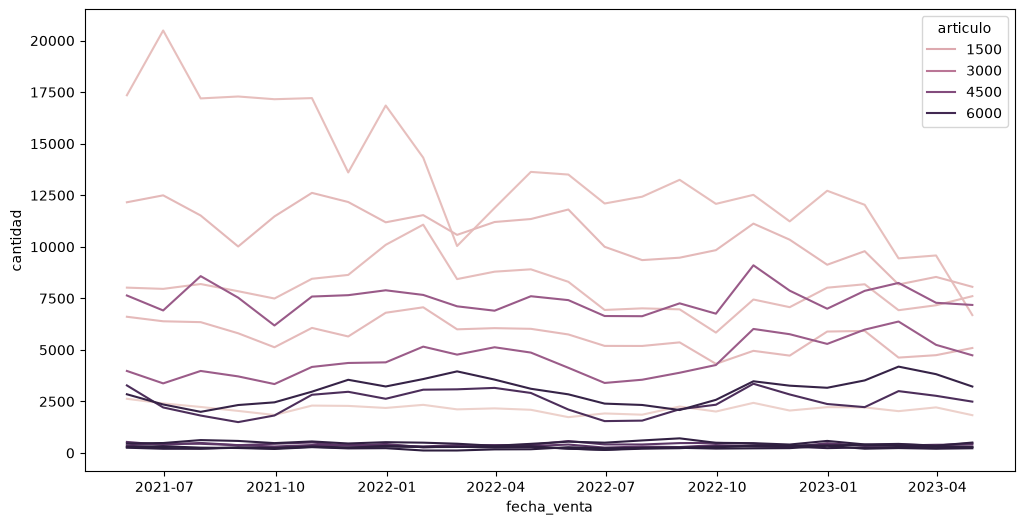

In [92]:
# 9. Temporal evolution of the variable "cantidad" by article

group = df.groupby(["articulo", pd.Grouper(key="fecha_venta", freq="ME")])["cantidad"].sum().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(data=group, x='fecha_venta', y='cantidad', hue='articulo') 


Text(0.5, 1.0, 'Temporal Evolution of "cantidad" by Article')

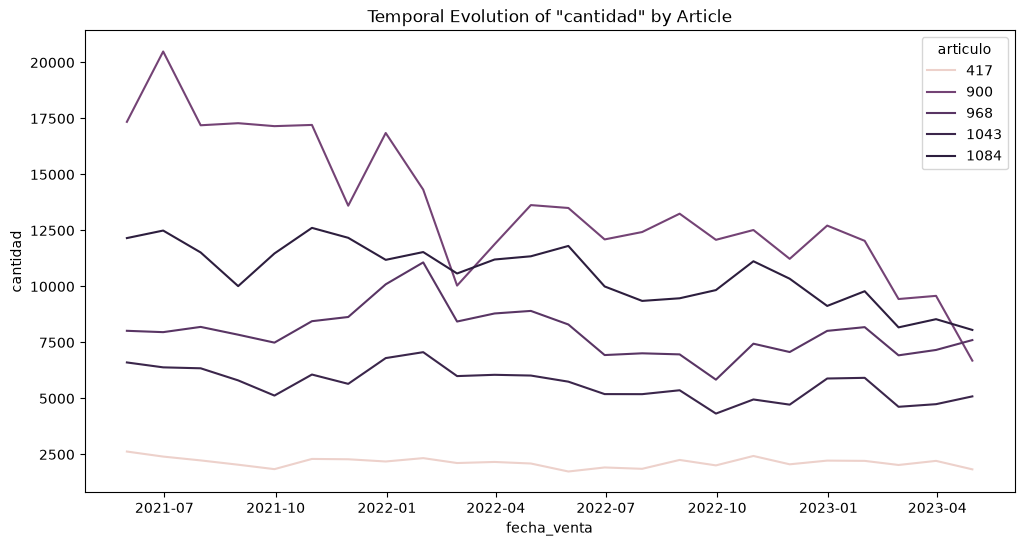

In [93]:
# 9. Temporal evolution of the variable "cantidad" by article

df_panaderia = df[df["familia"] == "PANADERIA"]

group = df_panaderia.groupby(["articulo", pd.Grouper(key="fecha_venta", freq="ME")])["cantidad"].sum().reset_index()
plt.figure(figsize=(12, 6))
sns.lineplot(data=group, x='fecha_venta', y='cantidad', hue='articulo') 
plt.title('Temporal Evolution of "cantidad" by Article')

- If we plot only the articles from "PANADERIA" family, we can see that article "900" is the main driver of the reported losses. And since it was the article with more units sold, makes sense that is driving the whole family trend

10. Is there any tendency or specific high or low selling seasons?

- Overall, in summer there are lower amount of selling units, and over christmas season there is a peak of selling units. This is a general trend observed in the previous plots

11. Apply a statistical test to see whethere we can see seasonal trends. Clue: Take the first difference and then do a correlation analysis


ADF Statistic:  -1.4639255514154301
p-value:  0.5512754434013831
Critical Values:
	1%: -3.440
	5%: -2.866
	10%: -2.569
 Non-stationary 


/tmp/ipykernel_2843/414543120.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.values)


<Axes: xlabel='fecha_venta', ylabel='cantidad'>

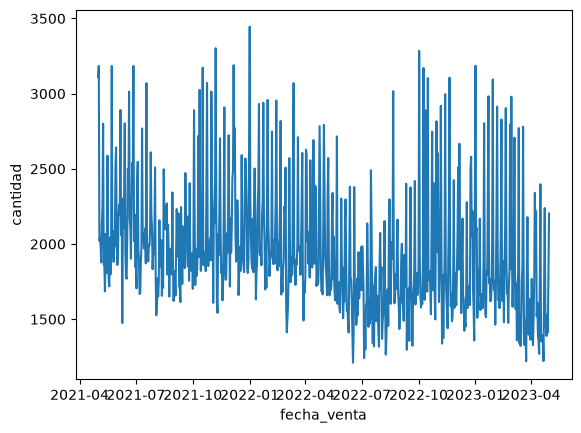

In [94]:
# 11. Check whether the process is following a seasnal patternw the test of Dickey-Fuller aumentada (ADF)
from statsmodels.tsa.stattools import adfuller

# Stationarity is a key property in time series analysis, 
# meaning that the statistical properties of a time series (such as its mean and variance) remain constant over time.
def check_stationarity(series):
    result = adfuller(series.values)

    print('ADF Statistic: ', result[0])
    print('p-value: ', result[1])
    print('Critical Values:')
    for key, value in result[4].items():
        print('\t%s: %.3f' % (key, value))

    if (result[1] <= 0.05) & (result[4]['5%'] > result[0]):
        print("\u001b[32m Stationary \u001b[0m")
    else:
        print("\x1b[31m Non-stationary \x1b[0m")

group = df.groupby([pd.Grouper(key="fecha_venta", freq="1D")])["cantidad"].sum().reset_index()
check_stationarity(group["cantidad"])
sns.lineplot(data=group, x='fecha_venta', y='cantidad')

- Desde el punto de vista estadístico, en general las ventas no son estacionarias


Product family: PANADERIA
ADF Statistic: -1.330
p-value: 0.6151
Non-stationary


/tmp/ipykernel_2843/3378645469.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


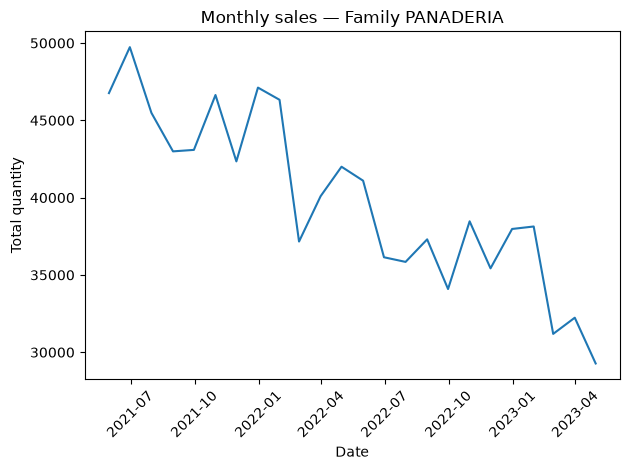


Product family: BOLLERIA
ADF Statistic: -2.816
p-value: 0.0561
Non-stationary


/tmp/ipykernel_2843/3378645469.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


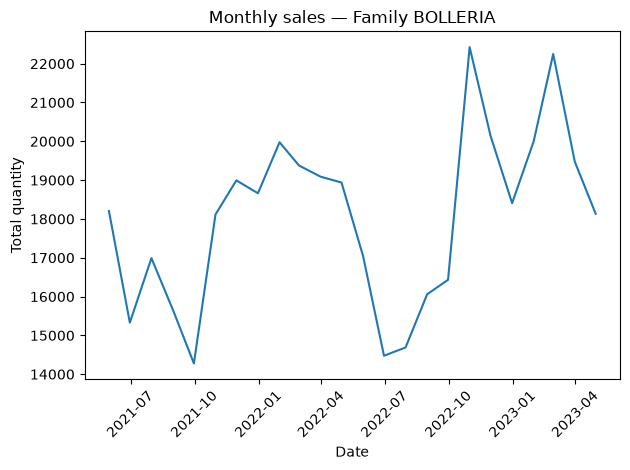


Product family: PASTELERIA
ADF Statistic: -2.091
p-value: 0.2480
Non-stationary


/tmp/ipykernel_2843/3378645469.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


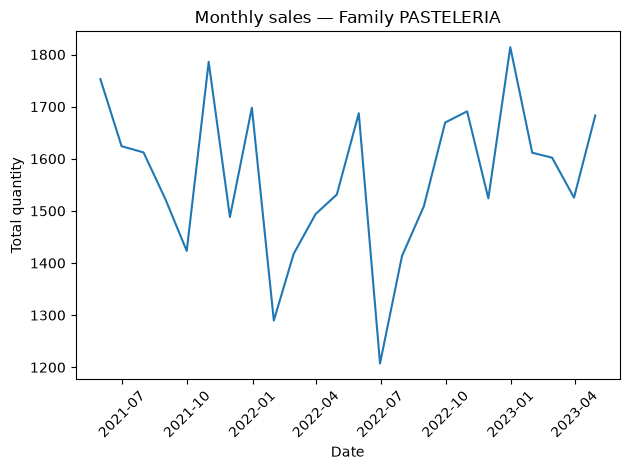

In [95]:
# 11. Check stationarity by product family using the ADF test

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

def check_stationarity(series):
    result = adfuller(series.dropna())

    adf_statistic = result[0]
    p_value = result[1]

    print(f"ADF Statistic: {adf_statistic:.3f}")
    print(f"p-value: {p_value:.4f}")

    if p_value <= 0.05:
        print("Stationary")
    else:
        print("Non-stationary")

# Loop over each product family
for familia in df["familia"].dropna().unique():

    print(f"\n{'='*50}")
    print(f"Product family: {familia}")
    print(f"{'='*50}")

    # Filter the current family and aggregate sales by month
    grupofamilia = (
        df[df["familia"] == familia]
        .groupby(pd.Grouper(key="fecha_venta", freq="ME"))["cantidad"]
        .sum()
        .reset_index()
    )

    # Check stationarity
    if len(grupofamilia) > 4 and grupofamilia["cantidad"].nunique() > 1:
        check_stationarity(grupofamilia["cantidad"])
    else:
        print("Insufficient data or no variation for the ADF test.")

    # Plot monthly sales
    sns.lineplot(data=grupofamilia, x="fecha_venta", y="cantidad")
    plt.title(f"Monthly sales — Family {familia}")
    plt.xlabel("Date")
    plt.ylabel("Total quantity")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

- If we distinguish them by family product, we can observe that unlike "PANADERIA", products from "BOLLERIA" and "PASTELERIA" are stationary

In [96]:
# 11. Taking the first difference 
# We can take the first difference to see if our time series becomes stationary. 
# This removes trends and stabilizes the variance of the time series, allowing it to be modeled.


group["cantidad_diff"] = group["cantidad"].diff().fillna(0)
check_stationarity(group["cantidad_diff"])

ADF Statistic: -12.370
p-value: 0.0000
Stationary


/tmp/ipykernel_2843/3378645469.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series.dropna())


<Axes: xlabel='fecha_venta', ylabel='cantidad_diff'>

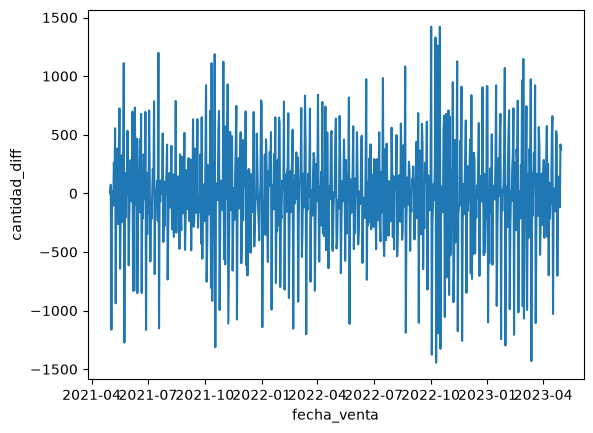

In [97]:
# 11. The new serie look like this

sns.lineplot(data=group, x='fecha_venta', y='cantidad_diff')

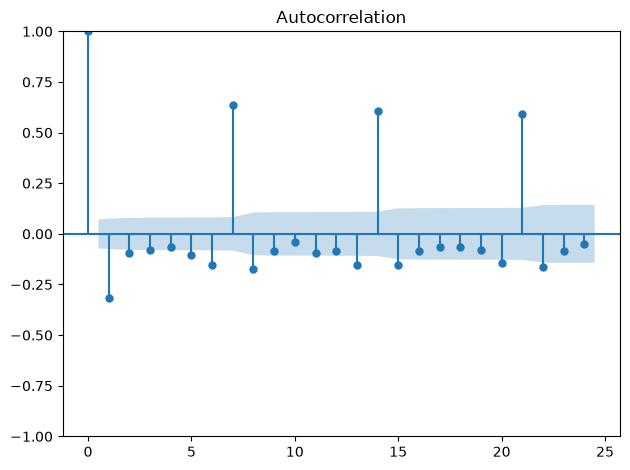

In [98]:
# 11. Autocorrelation analysis

# Generally speaking, this chart shows that a quantity value is directly related to its previous quantity value and last week's quantity value.
# It appears that there is weekly seasonality.

from statsmodels.graphics.tsaplots import plot_acf

plot_acf(group["cantidad_diff"],lags=24)
plt.tight_layout()
plt.show()

12. Without applying first-order differencing, create new date-related columns from the fecha_venta variable (week of the year, month of the year, day of the week, day of the month, and day of the year). Then, using different groupings and visualizations, check whether our autocorrelation analysis of the cantidad variable was showing us the correct patterns. If you find any particularly interesting or unexpected patterns in a plot, drill down into the analysis by increasing the level of granularity (e.g., 1. Overall quantity → 2. Quantity by product family → 3. Quantity by individual product).

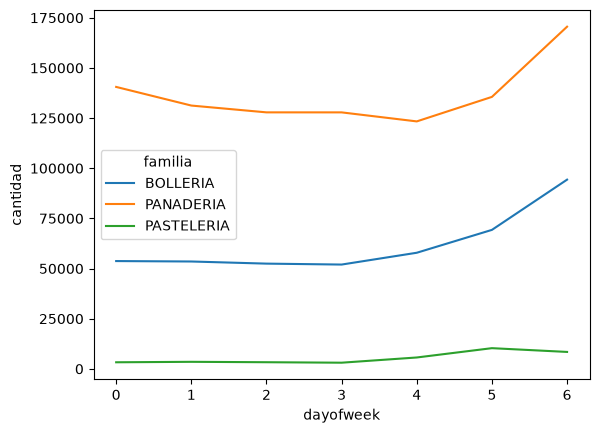

In [99]:
# 12. Week and month of the year

# Semana y mes del año
df["weekofyear"] = df["fecha_venta"].dt.isocalendar().week
df["monthofyear"] = df["fecha_venta"].dt.month

# Día de la semana, del mes y del año
df["dayofweek"] = df["fecha_venta"].dt.dayofweek #Lunes 0 y Domingo 6
df["dayofmonth"] = df["fecha_venta"].dt.day
df["dayofyear"] = df["fecha_venta"].dt.dayofyear

def graph_by_freq(freq, breakdown="familia", norm=False):
    group = df.groupby([breakdown, freq], as_index=False)["cantidad"].sum()

    if norm == True:
        group['cantidad'] = group.groupby(breakdown)['cantidad'].transform(normalize)

    sns.lineplot(data=group, x=freq, y='cantidad', hue=breakdown, markers=True)
    

# A nivel familia
graph_by_freq("dayofweek")

# As we found in our autocorrelation analysis,
# the quantity values may be related to their values from last week
# because there is a weekly purchasing pattern that repeats over time.

- Here we can extract the day, month or year from the variable "fechaventa" and group "cantidad" variable by day. We can see how PANADERIA, PASTELERIA and BOLLERIA articles are more sold over the weekend 

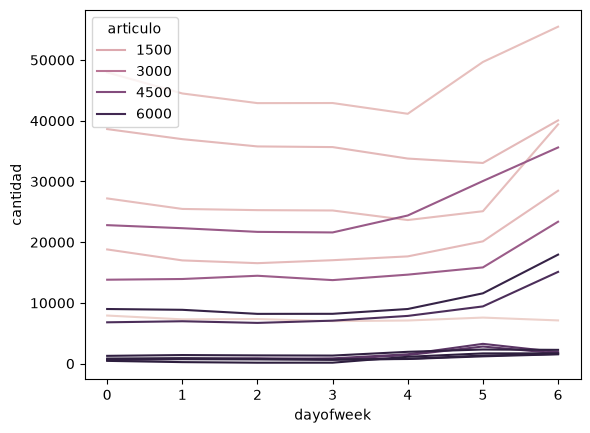

In [100]:
# 12. If we go to article level, we can see that the weekly pattern is more evident in some articles than in others.

# A nivel articulo
graph_by_freq("dayofweek", "articulo")

PANADERIA


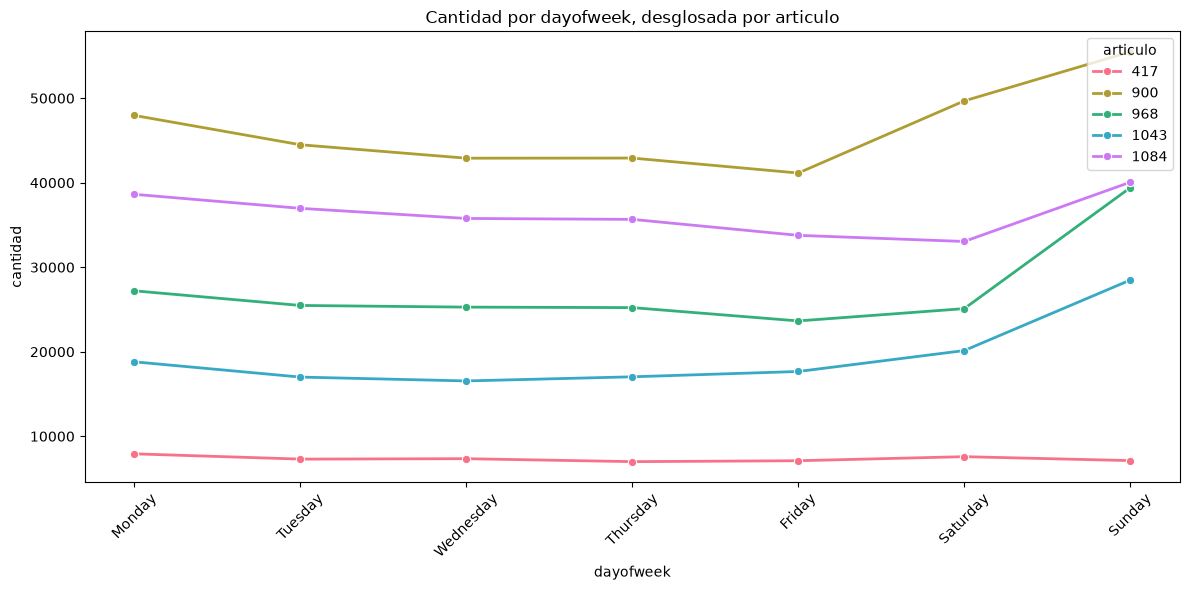

BOLLERIA


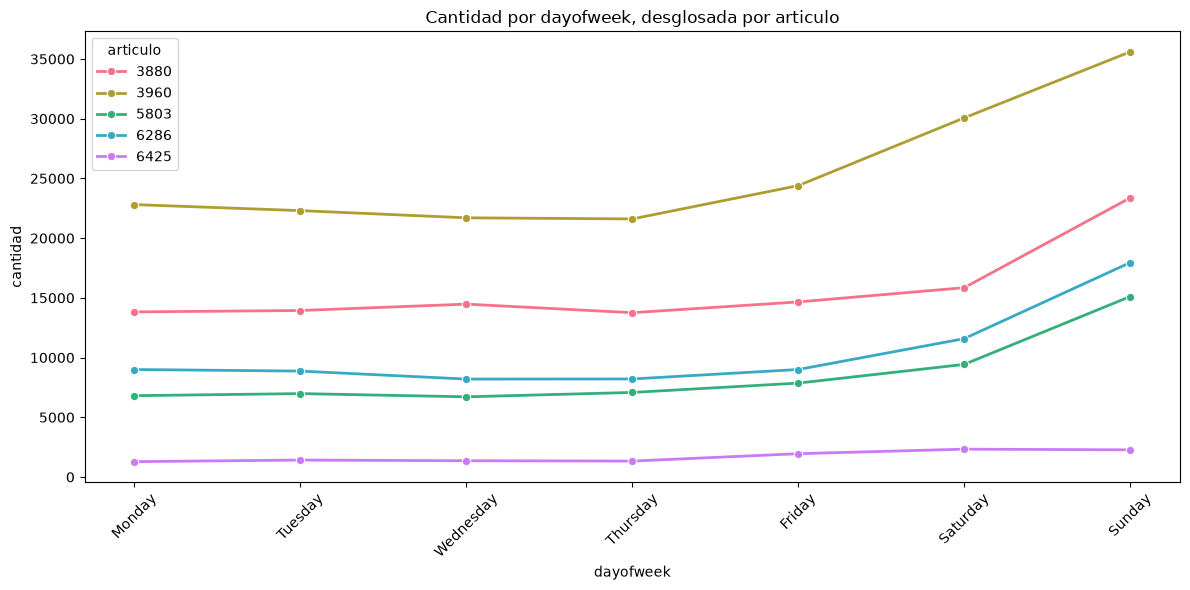

PASTELERIA


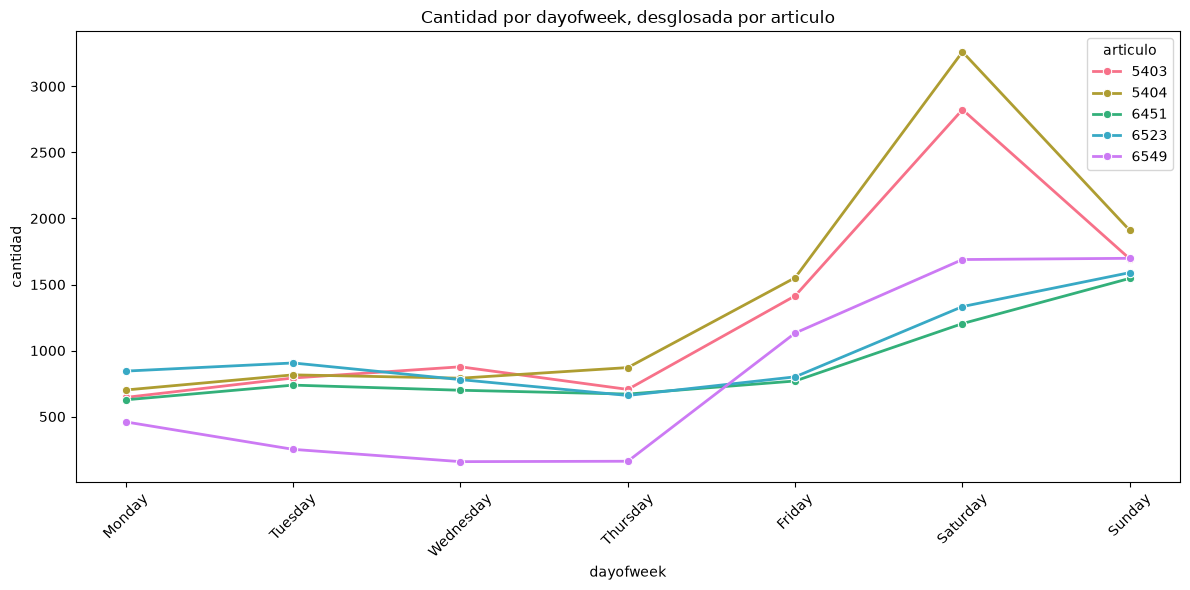

In [101]:
def graph_by_freq(freq, breakdown="familia", norm=False, data=None):
    if data is None:
        data = df

    group = data.groupby([breakdown, freq], as_index=False)["cantidad"].sum()

    if norm:
        group["cantidad"] = group.groupby(breakdown)["cantidad"].transform(normalize)

    n_colors = group[breakdown].nunique()
    palette = sns.color_palette("husl", n_colors)

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=group,
        x=freq,
        y="cantidad",
        hue=breakdown,
        palette=palette,
        marker="o",
        linewidth=2
    )

    # Replace day numbers with weekday names
    if freq == "dayofweek":
        days = ["Monday", "Tuesday", "Wednesday", "Thursday",
                "Friday", "Saturday", "Sunday"]
        plt.xticks(range(7), days, rotation=45)

    plt.title(f"Cantidad por {freq}, desglosada por {breakdown}")
    plt.tight_layout()
    plt.show()


for family in df["familia"].dropna().unique():
    print(family)
    family_df = df[df["familia"] == family]
    graph_by_freq("dayofweek", "articulo", data=family_df)

- Overall, all articles are more sold in saturday and sunday. However, specific PASTELERIA articles such as 5403 and 5404 selling units peak on saturday

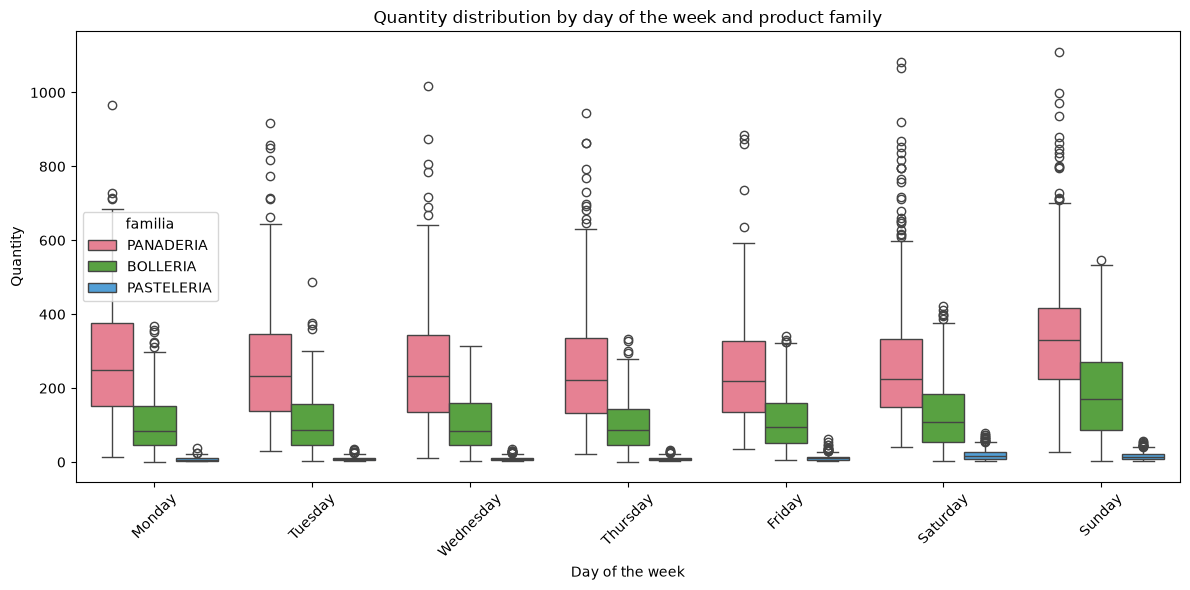

In [102]:
# 12. Boxplots

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="dayofweek",
    y="cantidad",
    hue="familia",
    palette="husl"
)

# Replace day numbers with weekday names
days = ["Monday", "Tuesday", "Wednesday", "Thursday",
        "Friday", "Saturday", "Sunday"]

plt.xticks(range(7), days, rotation=45)
plt.title("Quantity distribution by day of the week and product family")
plt.xlabel("Day of the week")
plt.ylabel("Quantity")
plt.tight_layout()
plt.show()

- We can see that overall, sunday is the top day to sell

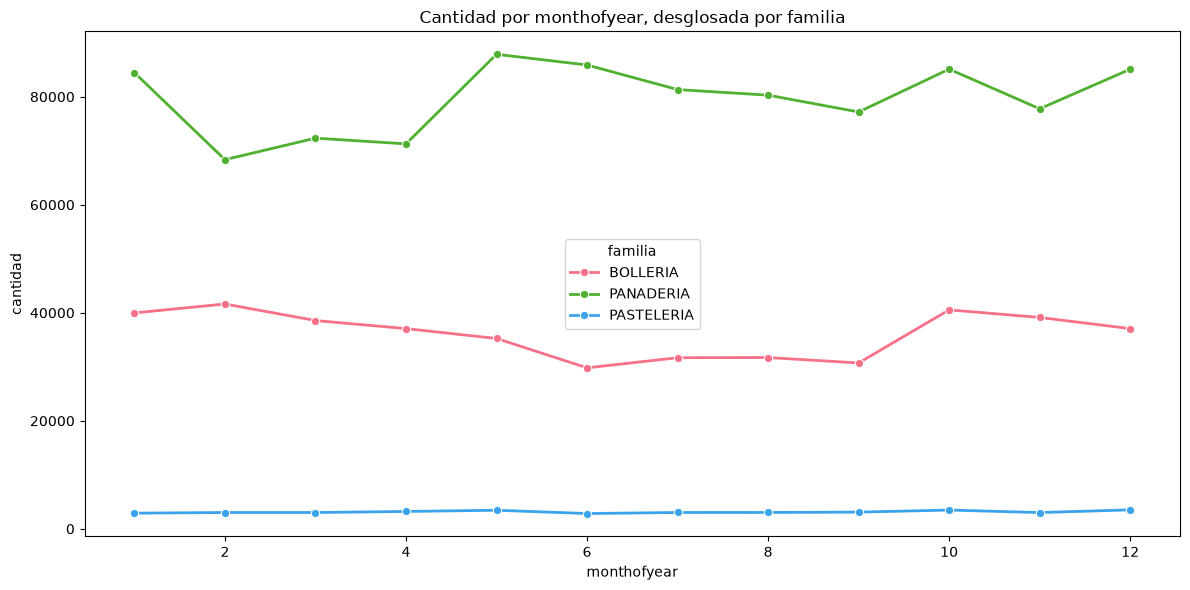

In [103]:
graph_by_freq("monthofyear")

- If we plot by months, we can see a peak of selling units in PANADERIA and BOLLERIA in May
- Regarding our product of interest "3960", belongs to "PASTELERIA" family, within its family is the second most sold product, and it is more sold over the weekend

*****

#### 4.3. Analysis of "3960" product performance in tearms of profits

In [104]:
df.head(5)

,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia,temp_w,tmin_w,tmax_w,prcp_w,wspd_w,pres_w,weekofyear,monthofyear,dayofweek,dayofmonth,dayofyear
0,PANADERIA,417,2021-05-01,NaN,4.038,72.0,290.736004,5,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121
1,PANADERIA,900,2021-05-01,NaN,0.865,651.0,563.114998,3,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121
2,PANADERIA,968,2021-05-01,NaN,2.163,450.0,973.350002,1,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121
3,PANADERIA,1043,2021-05-01,NaN,2.596,327.0,848.892002,2,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121
4,PANADERIA,1084,2021-05-01,NaN,0.865,423.0,365.895005,4,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121


PANADERIA


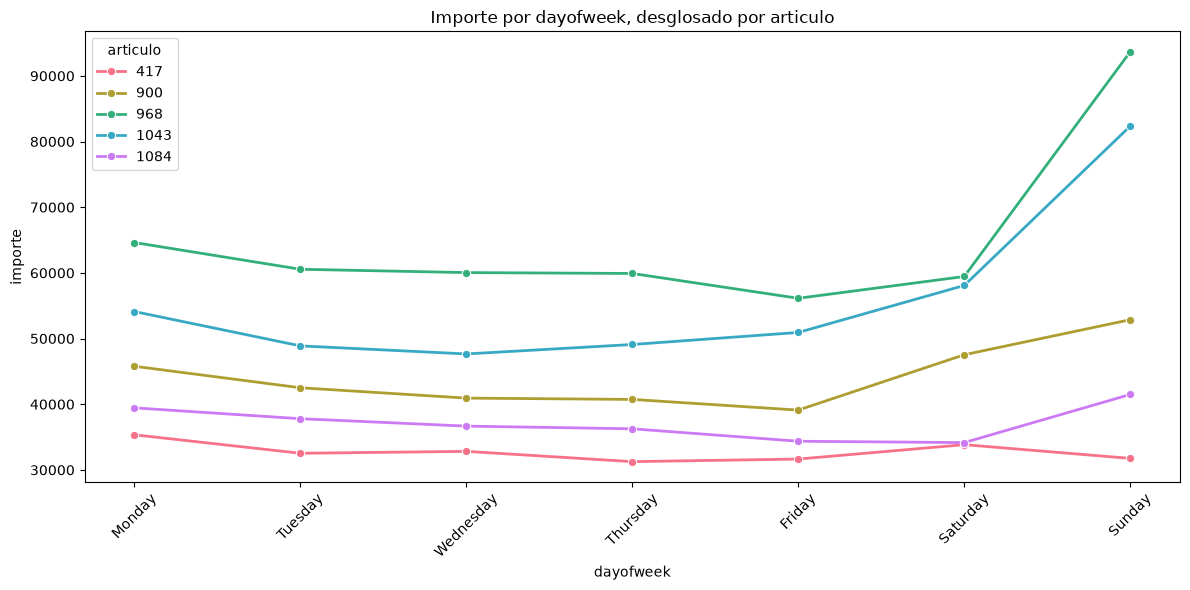

BOLLERIA


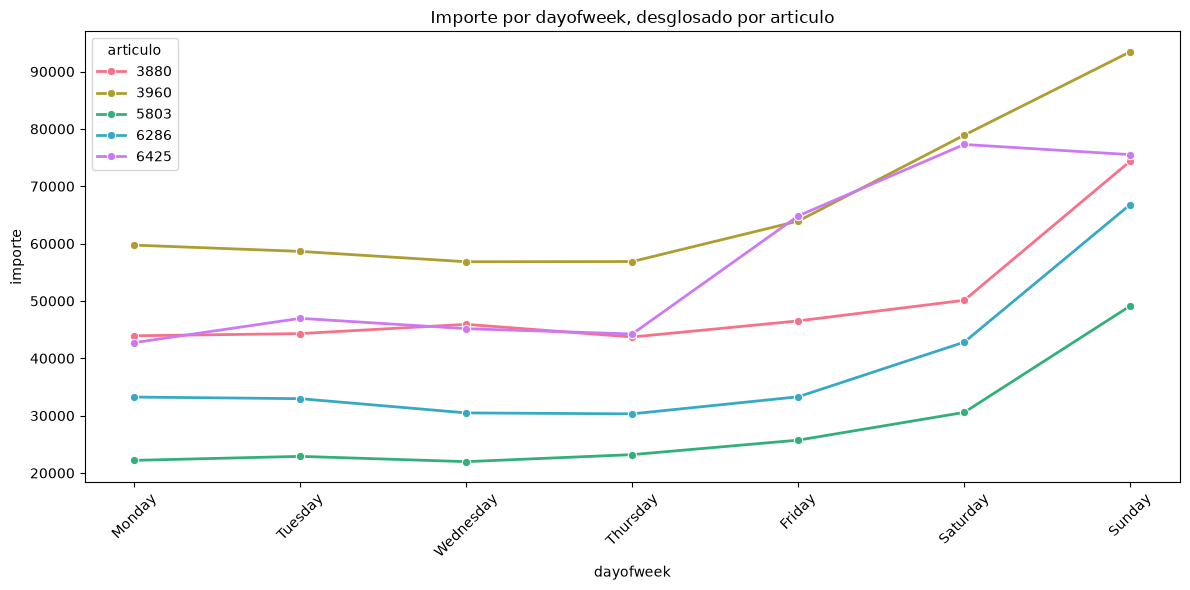

PASTELERIA


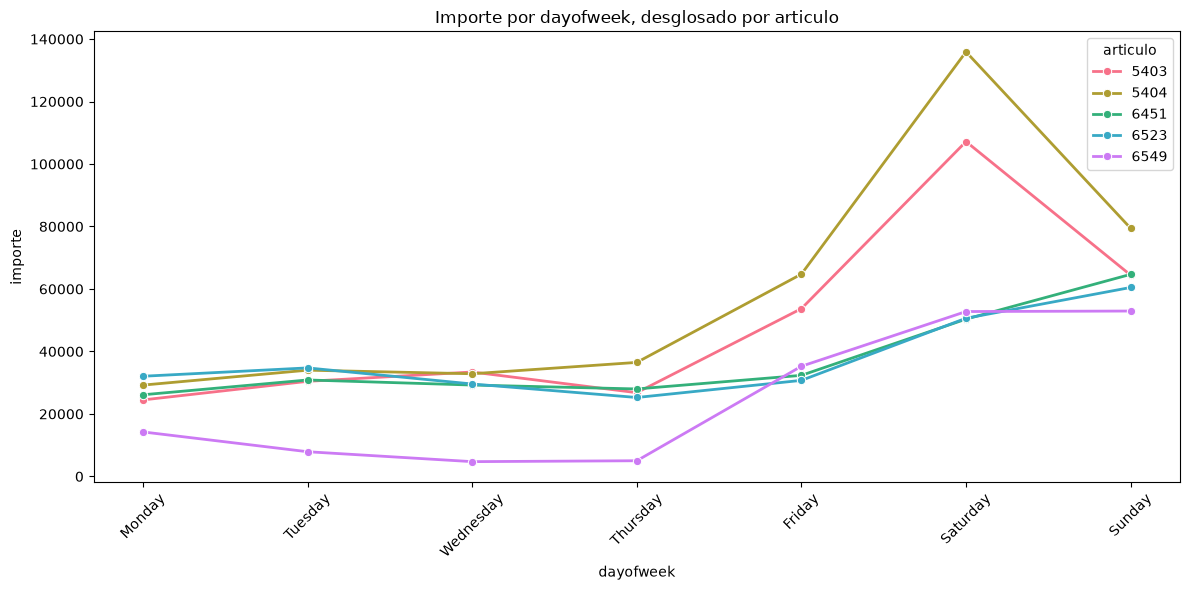

In [105]:
def graph_by_freq(freq, breakdown="familia", norm=False, data=None):
    if data is None:
        data = df

    group = data.groupby([breakdown, freq], as_index=False)["importe"].sum()

    if norm:
        group["importe"] = group.groupby(breakdown)["importe"].transform(normalize)

    n_colors = group[breakdown].nunique()
    palette = sns.color_palette("husl", n_colors)

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=group,
        x=freq,
        y="importe",
        hue=breakdown,
        palette=palette,
        marker="o",
        linewidth=2
    )
    
    # Replace day numbers with weekday names
    if freq == "dayofweek":
        days = ["Monday", "Tuesday", "Wednesday", "Thursday",
                "Friday", "Saturday", "Sunday"]
        plt.xticks(range(7), days, rotation=45)

    plt.title(f"Importe por {freq}, desglosado por {breakdown}")
    plt.xticks(range(7)) if freq == "dayofweek" else None
    plt.tight_layout()
    plt.show()


for family in df["familia"].dropna().unique():
    print(family)
    family_df = df[df["familia"] == family]
    graph_by_freq("dayofweek", "articulo", data=family_df)

- By checking by "importe" instead of "cantidad", we can see new things:
    - In PANADERIA, the article most sold ("900") is not the one with the highest billing, instead, the article with the highest billing is 968
    - IN BOLLERIA, our article "3960" is the most sold and the one with more "importe". On the other hand, although article 6425 is less sold than 3880 its "importe" is higher, indicating that it is a more expensive article. And, even it is less sold, it is the second most "profitable" article in terms of its billing
    - IN PASTELERIA, articles follow the same pattern in terms of amount/importe

*****

#### 4.3. Análisis de la variable a predecir frente al resto de variables

13. Is purchasing behavior (the “quantity” variable) higher on holidays than on non-holidays?

In [106]:
df.head(5)

,familia,articulo,fecha_venta,festivo,precio,cantidad,importe,orden_articulo_familia,temp_w,tmin_w,tmax_w,prcp_w,wspd_w,pres_w,weekofyear,monthofyear,dayofweek,dayofmonth,dayofyear
0,PANADERIA,417,2021-05-01,NaN,4.038,72.0,290.736004,5,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121
1,PANADERIA,900,2021-05-01,NaN,0.865,651.0,563.114998,3,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121
2,PANADERIA,968,2021-05-01,NaN,2.163,450.0,973.350002,1,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121
3,PANADERIA,1043,2021-05-01,NaN,2.596,327.0,848.892002,2,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121
4,PANADERIA,1084,2021-05-01,NaN,0.865,423.0,365.895005,4,17.2,11.9,22.8,0.0,14.2,1014.0,17,5,5,1,121


es_festivo
No festivo    9513
Festivo        809
Name: count, dtype: int64


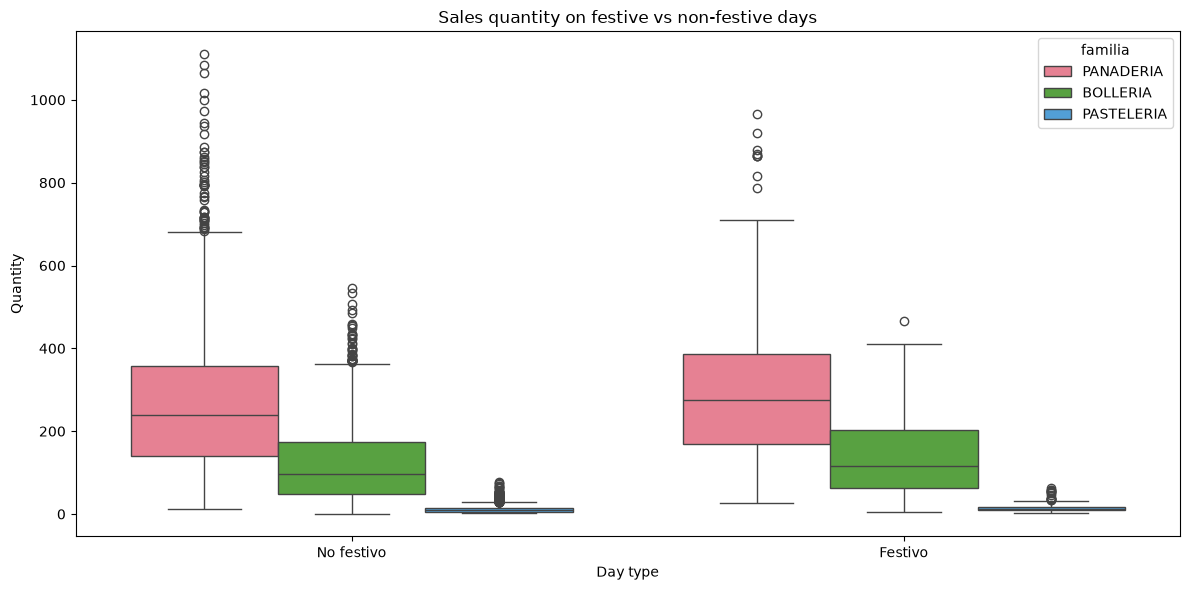

In [107]:
# 13. Compare sales on festive and non-festive days

# 1 = festive, 0 = non-festive
df["es_festivo"] = df["festivo"].notna().map({
    True: "Festivo",
    False: "No festivo"
})

print(df["es_festivo"].value_counts())

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="es_festivo",
    y="cantidad",
    hue="familia",
    palette="husl"
)

plt.title("Sales quantity on festive vs non-festive days")
plt.xlabel("Day type")
plt.ylabel("Quantity")
plt.tight_layout()
plt.show()

- It seems that in festivo days, the selling amounts are a slightly higher, but not much

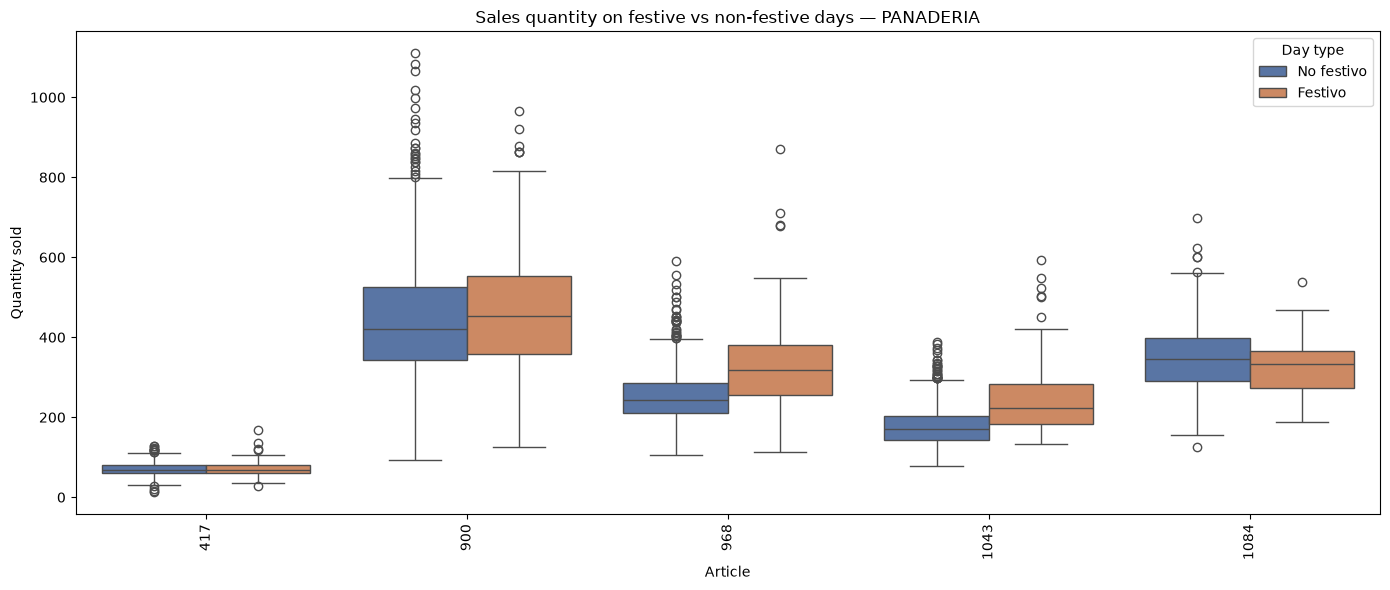

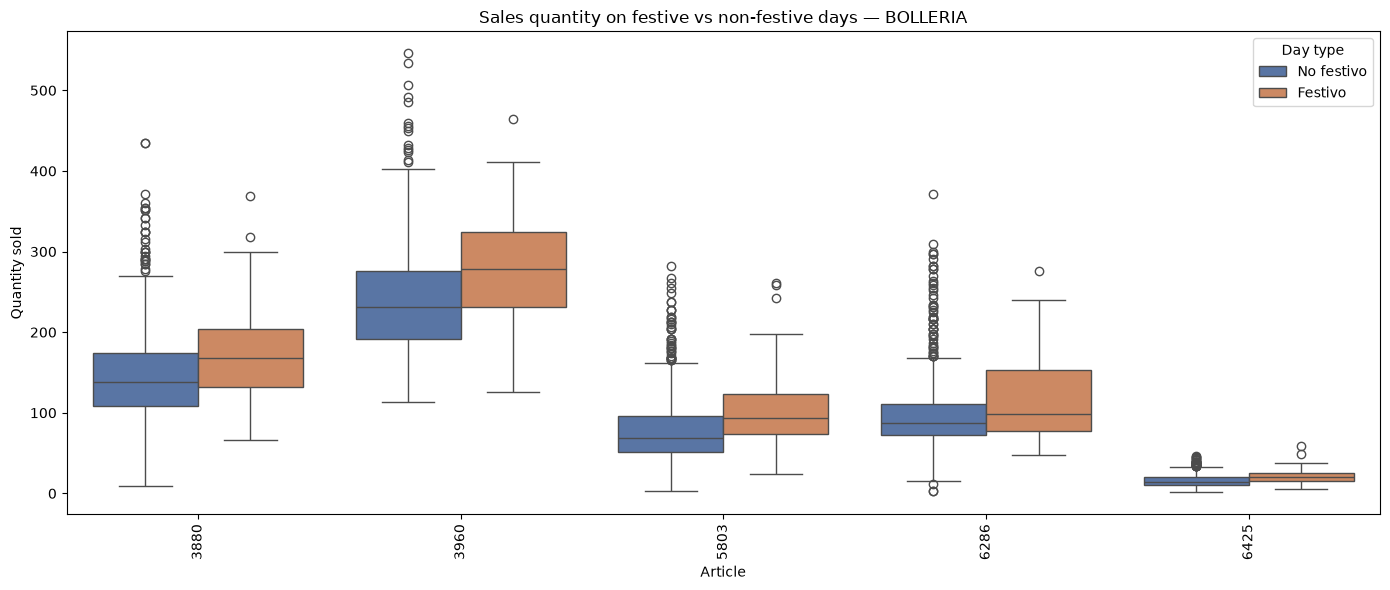

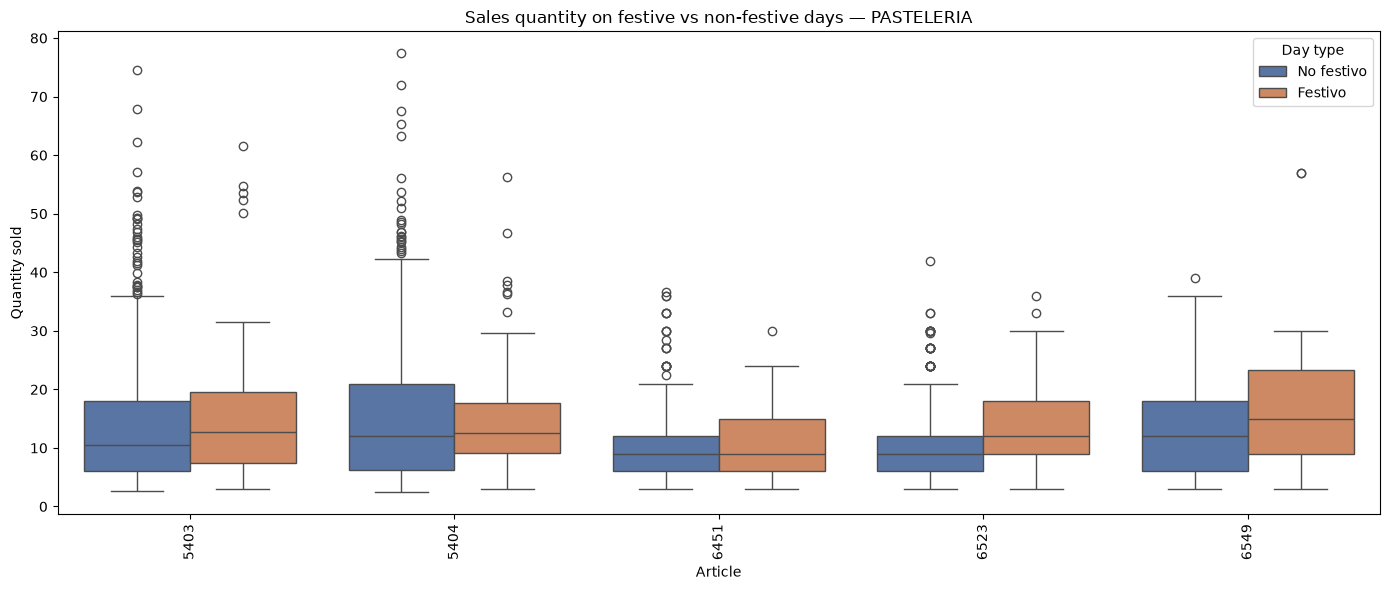

In [108]:
# 13. Compare festive vs non-festive sales for each family and article

import matplotlib.pyplot as plt
import seaborn as sns

# Classify festive and non-festive days
df["es_festivo"] = df["festivo"].notna().map({
    True: "Festivo",
    False: "No festivo"
})

# Loop over each product family
for family in df["familia"].dropna().unique():

    family_df = df[df["familia"] == family]

    plt.figure(figsize=(14, 6))

    sns.boxplot(
        data=family_df,
        x="articulo",
        y="cantidad",
        hue="es_festivo",
        hue_order=["No festivo", "Festivo"],
        palette=["#4C72B0", "#DD8452"]
    )

    plt.title(f"Sales quantity on festive vs non-festive days — {family}")
    plt.xlabel("Article")
    plt.ylabel("Quantity sold")
    plt.xticks(rotation=90)
    plt.legend(title="Day type")
    plt.tight_layout()
    plt.show()

- If we go to the article level, we can see certain articles in each family more sold in "festivo" such as "968" and "1043" in PANADERIA, all articles in BOLLERIA, and "6523" and "6549" in PASTELERIA

14. Is purchasing behavior (the “quantity” variable) higher when it rains than when it doesn’t?

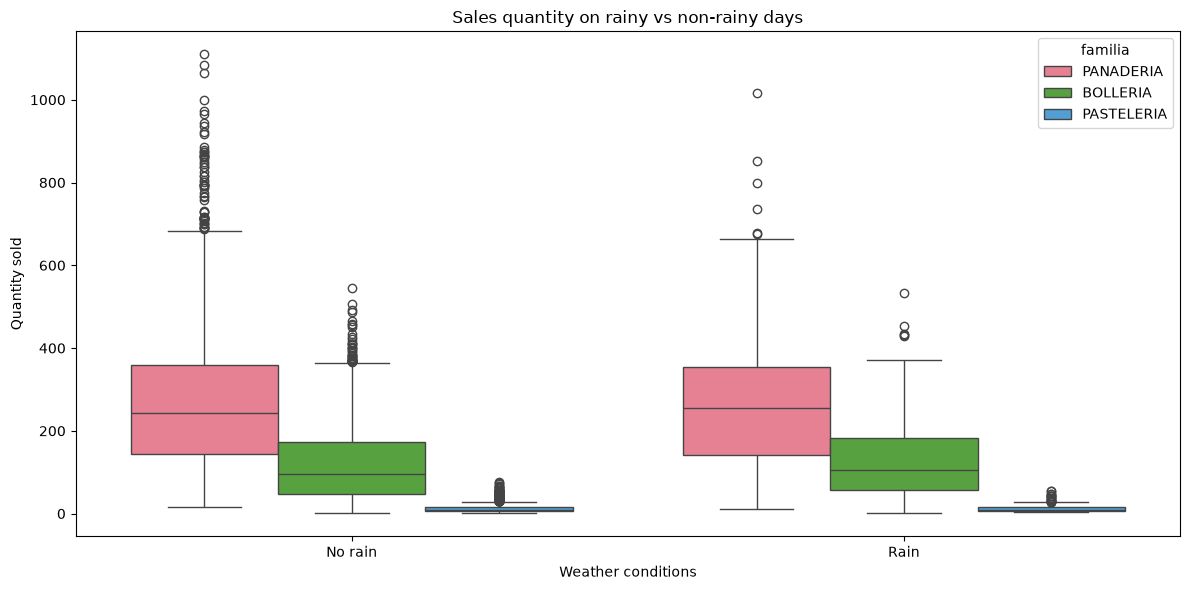

In [109]:
# 14. Analyze whether sales quantity depends on rainfall

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1 = rainy day, 0 = non-rainy day
df["lluvia"] = np.where(df["prcp_w"] > 0, 1, 0)

# Replace numerical labels with readable labels
df["lluvia_label"] = df["lluvia"].map({
    0: "No rain",
    1: "Rain"
})

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df,
    x="lluvia_label",
    y="cantidad",
    hue="familia",
    palette="husl"
)

plt.title("Sales quantity on rainy vs non-rainy days")
plt.xlabel("Weather conditions")
plt.ylabel("Quantity sold")
plt.tight_layout()
plt.show()

- In general, there is no much difference upon the rain

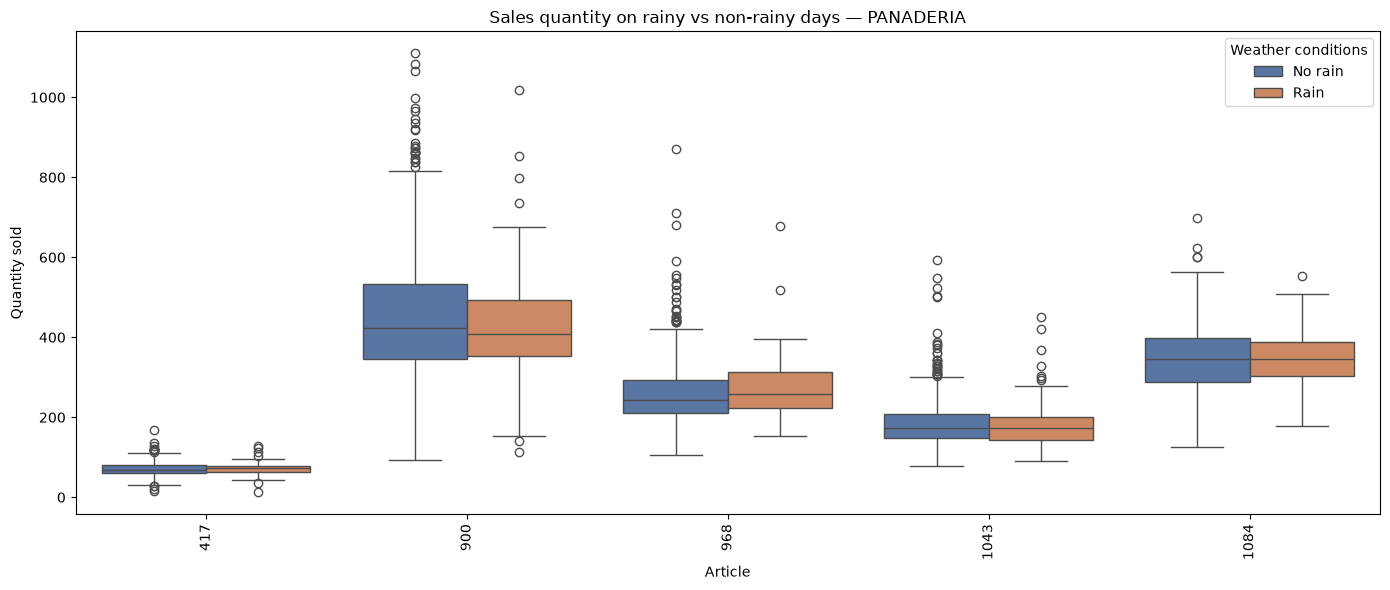

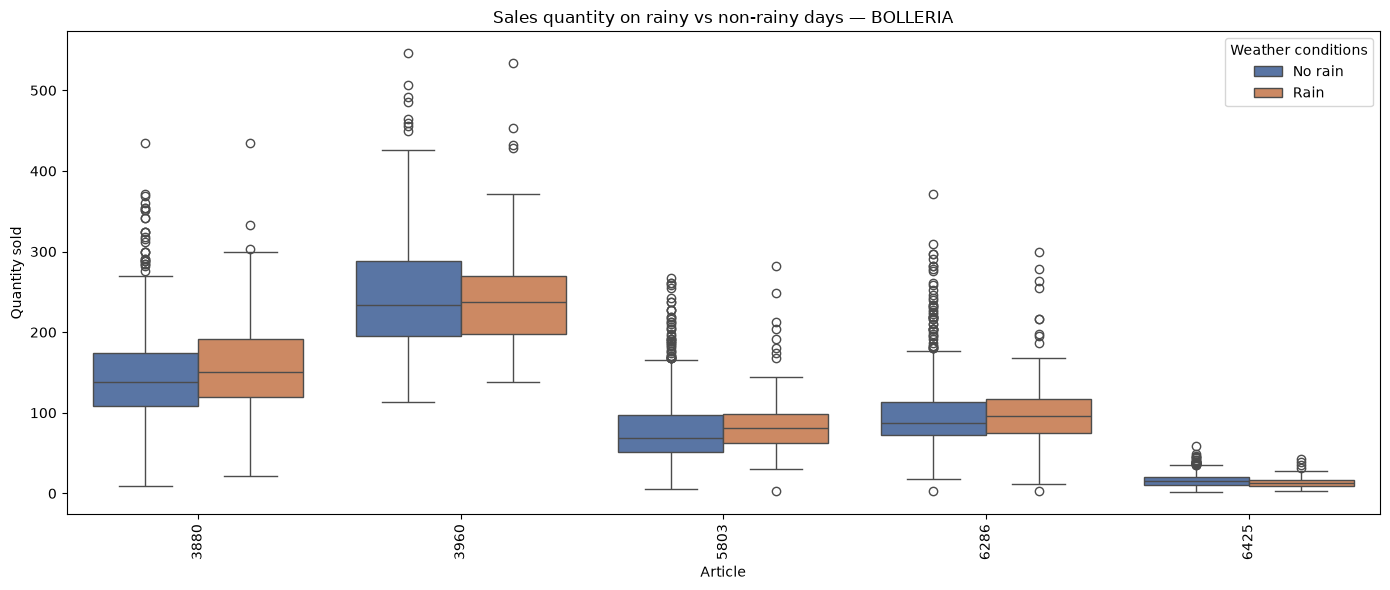

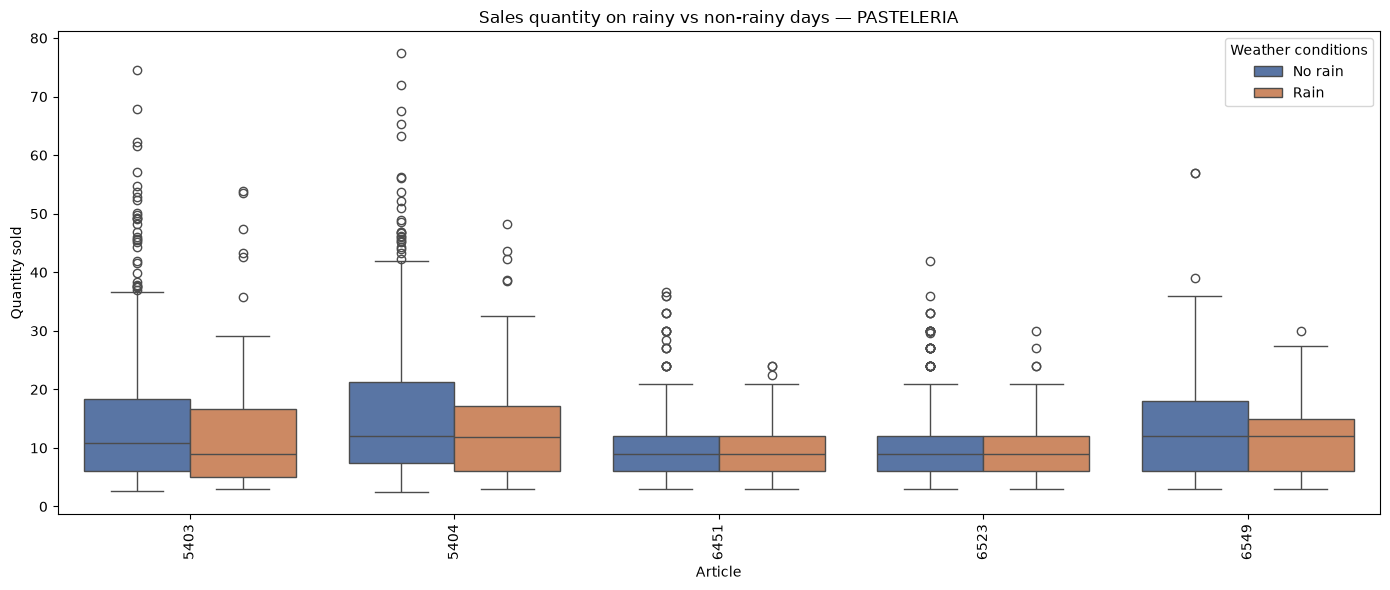

In [110]:
# 14. Compare rainy vs non-rainy sales for each family and article

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Classify rainy and non-rainy days
df["lluvia"] = np.where(
    df["prcp_w"].isna(),
    np.nan,
    np.where(df["prcp_w"] > 0, 1, 0)
)

df["lluvia_label"] = df["lluvia"].map({
    0: "No rain",
    1: "Rain"
})

# Loop over each product family
for family in df["familia"].dropna().unique():

    family_df = df[df["familia"] == family].dropna(subset=["lluvia_label"])

    plt.figure(figsize=(14, 6))

    sns.boxplot(
        data=family_df,
        x="articulo",
        y="cantidad",
        hue="lluvia_label",
        hue_order=["No rain", "Rain"],
        palette=["#4C72B0", "#DD8452"]
    )

    plt.title(f"Sales quantity on rainy vs non-rainy days — {family}")
    plt.xlabel("Article")
    plt.ylabel("Quantity sold")
    plt.xticks(rotation=90)
    plt.legend(title="Weather conditions")
    plt.tight_layout()
    plt.show()

- Even if we divide them by articles within each family, we see that raining does not affect to selling amount

15. Divide the “tavg_w” variable into quintiles and use a bar chart to show whether the “quantity” variable is higher in any of its quintiles.

In [111]:
df.columns


Index(['familia', 'articulo', 'fecha_venta', 'festivo', 'precio', 'cantidad',
       'importe', 'orden_articulo_familia', 'temp_w', 'tmin_w', 'tmax_w',
       'prcp_w', 'wspd_w', 'pres_w', 'weekofyear', 'monthofyear', 'dayofweek',
       'dayofmonth', 'dayofyear', 'es_festivo', 'lluvia', 'lluvia_label'],
      dtype='str')

<Axes: xlabel='quintiles_temp', ylabel='cantidad'>

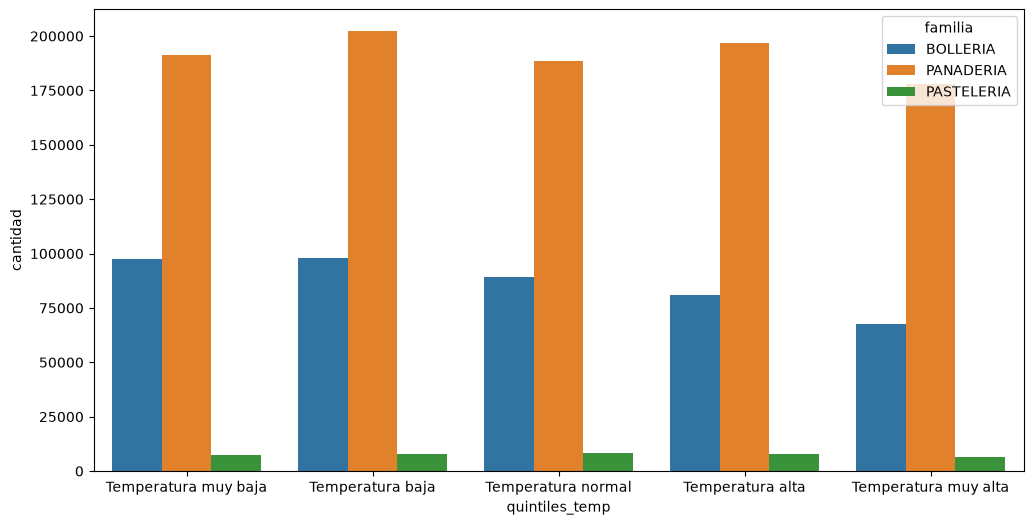

In [112]:
# 15. Analysis of the mean temperature related to selling units

labels_tavg = ['Temperatura muy baja',
               'Temperatura baja',
               'Temperatura normal',
               'Temperatura alta',
               'Temperatura muy alta']

df['quintiles_temp'] = pd.qcut(df['temp_w'], q=5, labels=labels_tavg)

group = df.groupby(["familia", "quintiles_temp"])["cantidad"].sum().reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(data=group, x='quintiles_temp', y='cantidad', hue='familia')
#fig = px.bar(group, x='quintiles_temp', y='cantidad', color="familia",barmode='group')
#fig.show()

- We can see that BOLLERIA articles are less sold whenever the temperature is higher

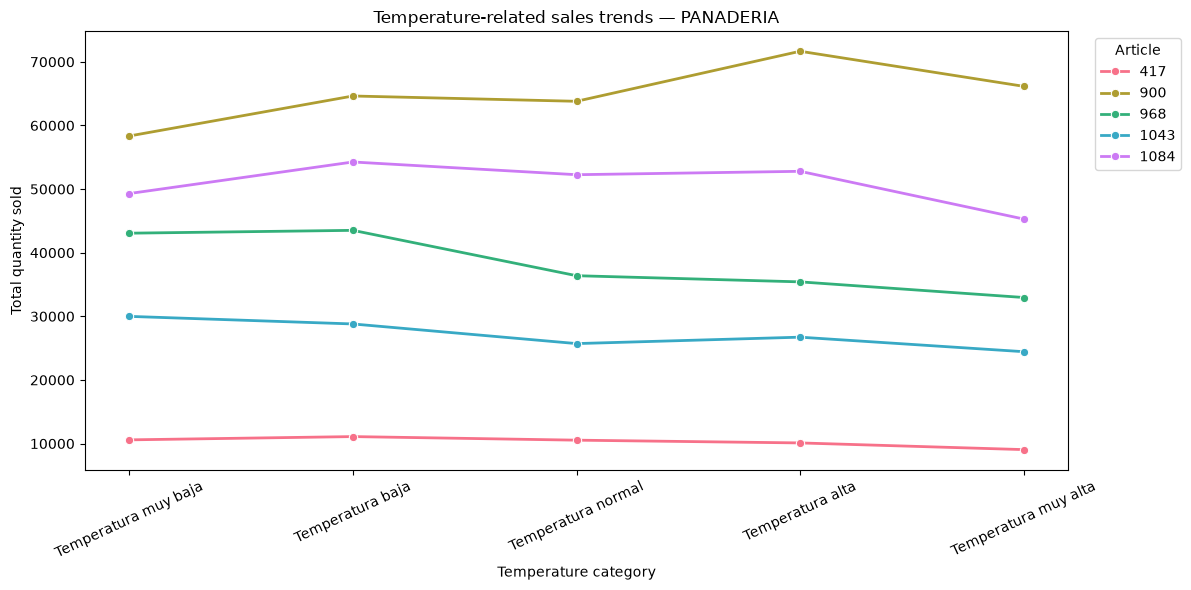

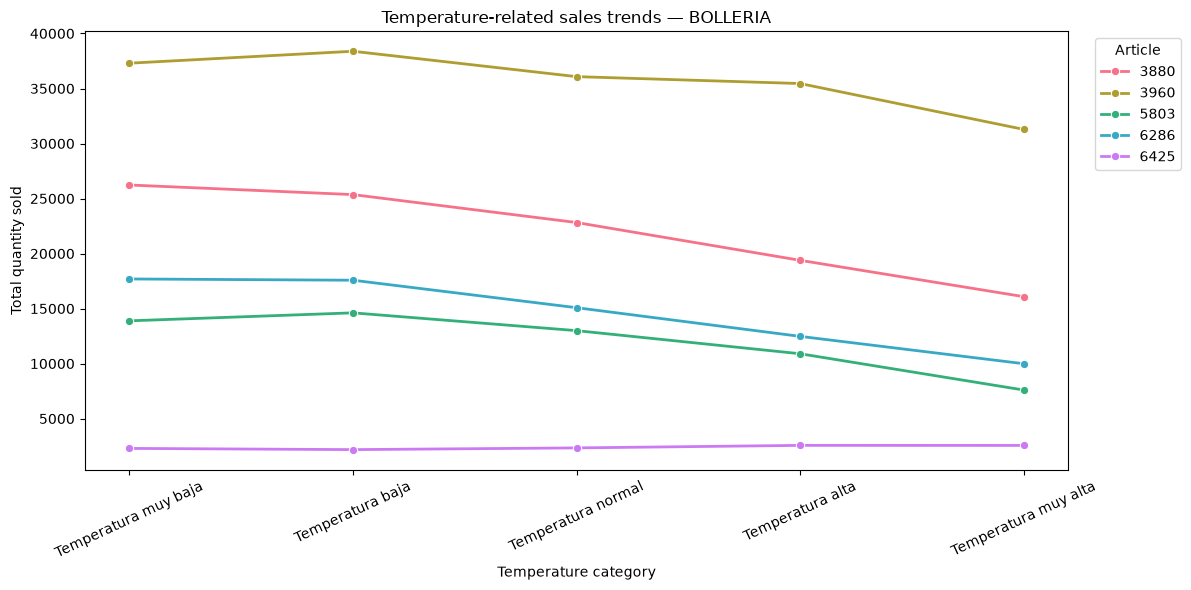

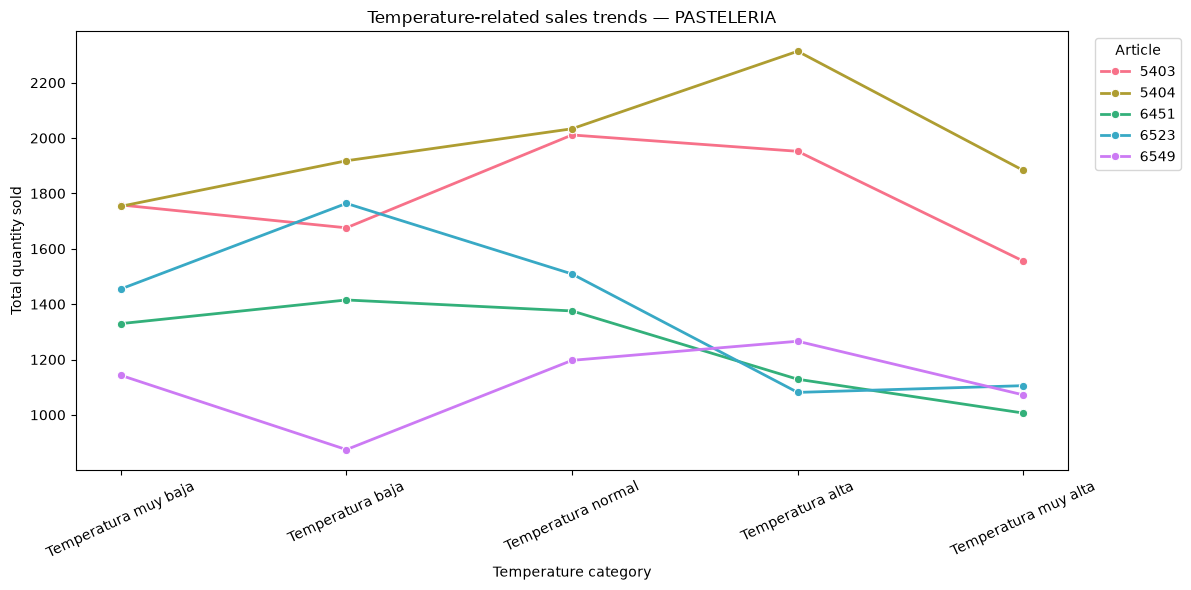

In [114]:
# 15. Analyze temperature-related sales trends by family and article

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

labels_tavg = [
    "Temperatura muy baja",
    "Temperatura baja",
    "Temperatura normal",
    "Temperatura alta",
    "Temperatura muy alta"
]

# Categorize temperature into quintiles
df["quintiles_temp"] = pd.qcut(
    df["temp_w"],
    q=5,
    labels=labels_tavg,
    duplicates="drop"
)

# Aggregate quantity sold by family, article and temperature category
group = (
    df.groupby(
        ["familia", "articulo", "quintiles_temp"],
        observed=True
    )["cantidad"]
    .sum()
    .reset_index()
)

# Plot each family separately
for family in df["familia"].dropna().unique():

    family_df = group[group["familia"] == family]

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=family_df,
        x="quintiles_temp",
        y="cantidad",
        hue="articulo",
        palette=sns.color_palette(
            "husl", family_df["articulo"].nunique()
        ),
        marker="o",
        linewidth=2
    )

    plt.title(f"Temperature-related sales trends — {family}")
    plt.xlabel("Temperature category")
    plt.ylabel("Total quantity sold")
    plt.xticks(rotation=25)
    plt.legend(title="Article", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

- In PANADERIA, article "900" is more sold with higher temperatures
- In BOLLERIA, in general, all articles are less sold with higher temperatures
- In PASTELERIA, there are articles more sold in low-temperatures such as "6451" and "6523" and other more sold in higher temps such as "5404" and 6549"

16. Does a price increase reduce the propensity to consume a good?

<Axes: xlabel='precio', ylabel='cantidad'>

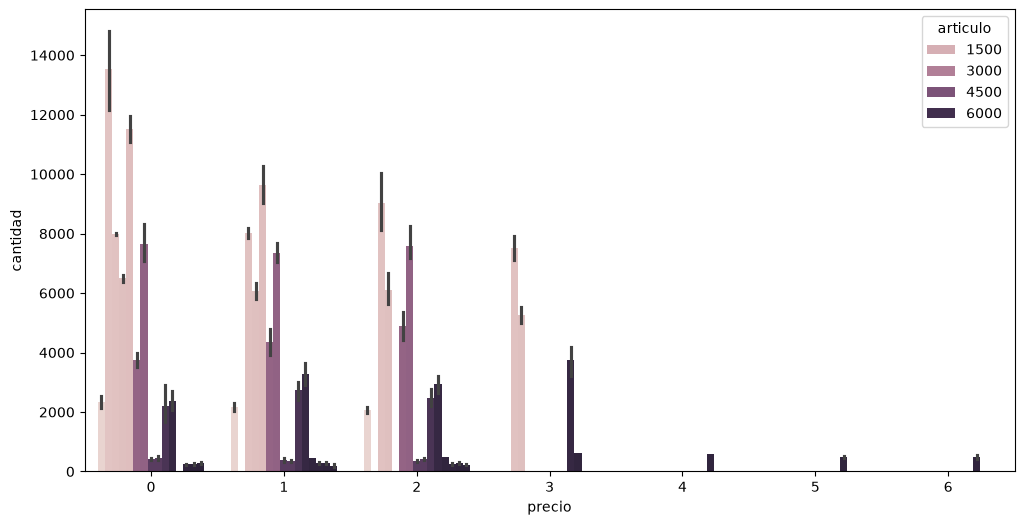

In [ ]:
# 16

def function_variations(x):
    list_unique = x.unique()
    len_list = len(list_unique)

    if len_list > 1:
        return 1
    else:
        return 0

group = df.groupby(["articulo",
                    pd.Grouper(key="fecha_venta", freq="ME"),
                    "familia"]).agg({"cantidad": "sum",
                                     "precio": function_variations}).reset_index()

group["precio"] = group.groupby("articulo")["precio"].transform("cumsum")
group["precio"] = group["precio"].astype(object)

plt.figure(figsize=(12, 6))
sns.barplot(data=group, x='precio', y='cantidad', hue='articulo')
#fig = px.box(group, x="precio", y="cantidad", color='articulo')
#
# fig.show()


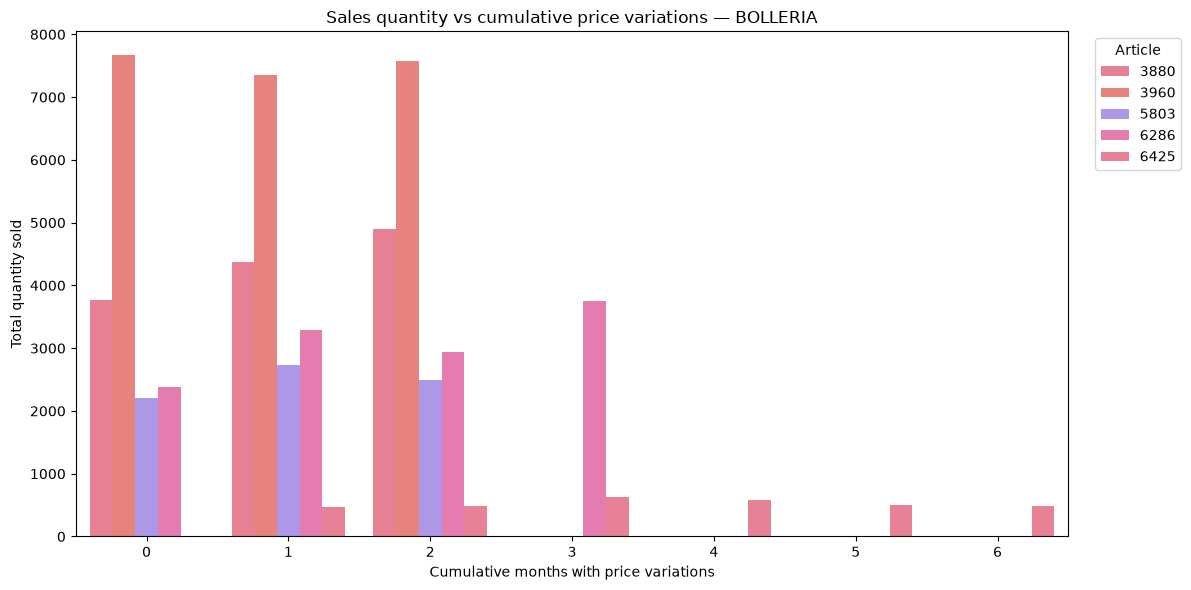

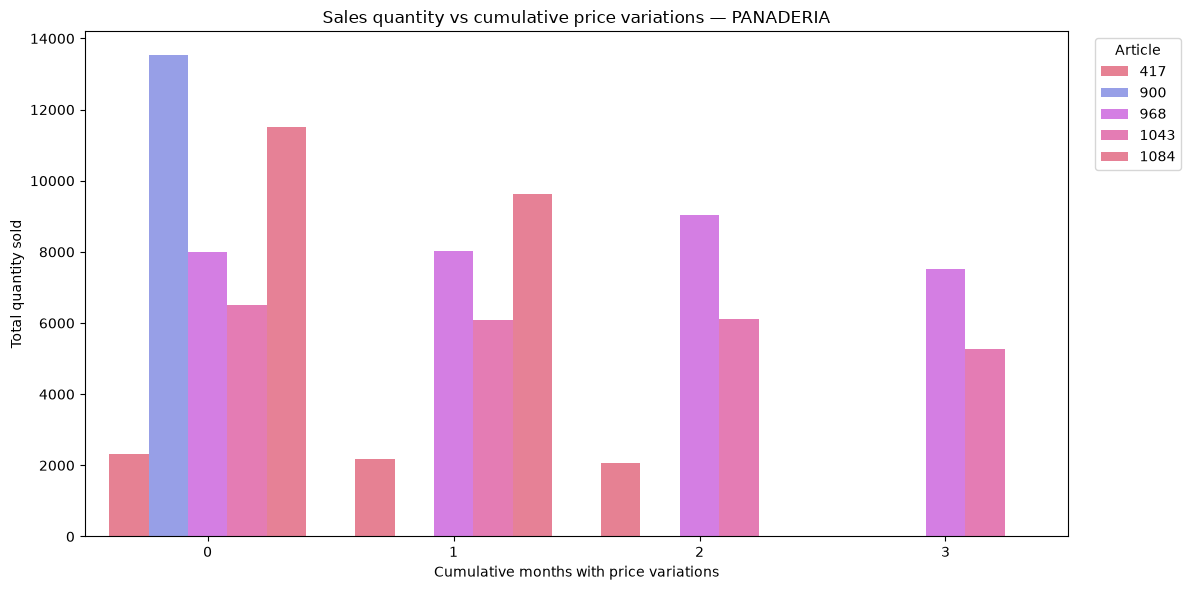

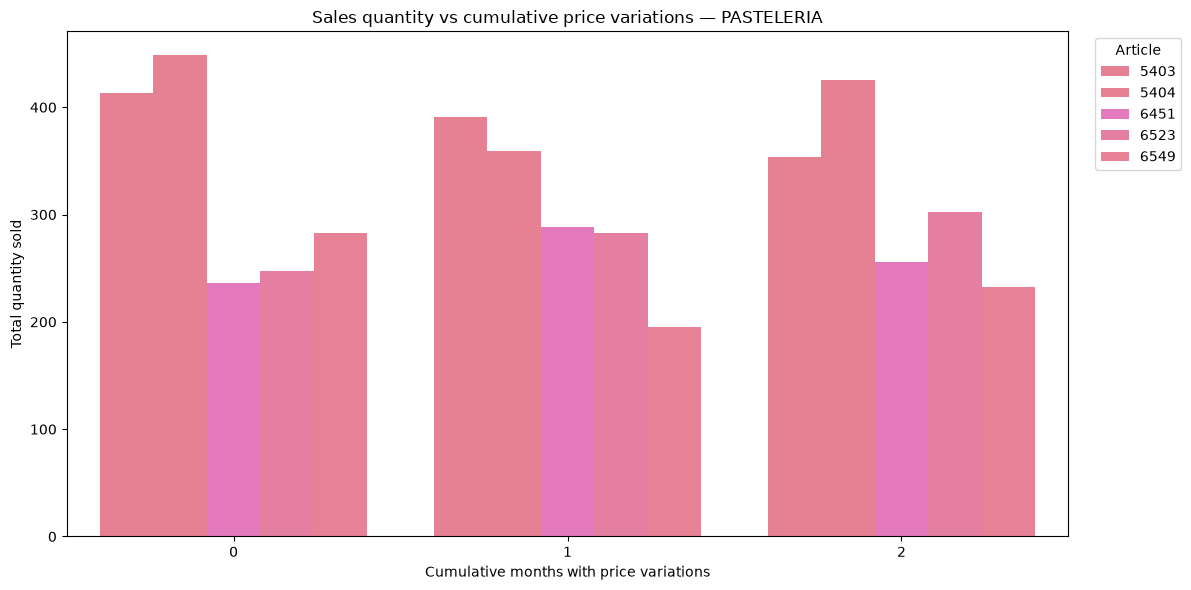

In [117]:
# 16. Analyze sales quantity and price variations by family

def function_variations(x):
    return int(x.nunique() > 1)

# Aggregate monthly sales by article and family
group = (
    df.groupby(
        ["familia", "articulo", pd.Grouper(key="fecha_venta", freq="ME")]
    )
    .agg(
        cantidad=("cantidad", "sum"),
        precio=("precio", function_variations)
    )
    .reset_index()
)

# Cumulative count of months with price variations, by article
group["precio"] = (
    group.groupby(["familia", "articulo"])["precio"].cumsum()
)

# Plot each family separately
for family in group["familia"].dropna().unique():

    family_df = group[group["familia"] == family]

    plt.figure(figsize=(12, 6))

    sns.barplot(
        data=family_df,
        x="precio",
        y="cantidad",
        hue="articulo",
        palette="husl",
        errorbar=None
    )

    plt.title(f"Sales quantity vs cumulative price variations — {family}")
    plt.xlabel("Cumulative months with price variations")
    plt.ylabel("Total quantity sold")
    plt.legend(title="Article", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

- There is no a clear trend, although certain articles are quite stable despite price variations such as those in "PASTELERIA" while, articles in BOLLERIA seem to have less selling units in those articles with more variable prices

*****